---
# TP LABO - Fenómeno de El Niño
---

Poner algo que diga de qué va el colab, despues se completa, son detalles

# 🔍 3.1 Exploración inicial de los Datasets

### Dataset "smn_estaciones_meteorologicas21-26.xlsx":

In [73]:
#Importamos las librerías que vamos a utilizar
import pandas as pd #para manejo de archivos de datos
import numpy as np #para realizar cálculos numéricos y matemáticos
import matplotlib.pyplot as plt #para graficar

In [74]:
# Buscamos el archivo en el GitHub
# Apunta a la carpeta DF/ del repositorio en GitHub. Será el mismo URL para todos los Dataframes.
URL = "https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/"

print(URL + "smn_estaciones_meteorologicas21-26.xlsx")   # así se arma la dirección de cada archivo

https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/smn_estaciones_meteorologicas21-26.xlsx


In [75]:
#Cargamos los datos
estaciones = pd.read_excel(URL + "smn_estaciones_meteorologicas21-26.xlsx")   # read_excel: leer una planilla de Excel

In [76]:
# Leemos las primeras 5 lineas del principio:
estaciones.head()

,NRO_OMM,NOMBRE,PROVINCIA,LATITUD,LONGITUD,ALTURA
0,87544,PEHUAJO AERO,BUENOS AIRES,-35.84070,-61.85978,87
1,87548,JUNIN AERO,BUENOS AIRES,-34.55251,-60.93127,81
2,87550,NUEVE DE JULIO,BUENOS AIRES,-35.43899,-60.88191,76
3,87553,SAN FERNANDO AERO,BUENOS AIRES,-34.45502,-58.58449,5
4,87563,LAS FLORES,BUENOS AIRES,-36.04149,-59.13724,36


In [77]:
# Leemos las últimas 5 lineas del dataset:
estaciones.tail()

,NRO_OMM,NOMBRE,PROVINCIA,LATITUD,LONGITUD,ALTURA
87,87470,EL TRÉBOL,SANTA FE,-32.19216,-61.71198,96
88,87129,SANTIAGO DEL ESTERO AERO,SANTIAGO DEL ESTERO,-27.75481,-64.29980,199
89,87934,RÍO GRANDE B.A.,TIERRA DEL FUEGO,-53.78026,-67.75871,22
90,87938,USHUAIA AERO,TIERRA DEL FUEGO,-54.84005,-68.30342,57
91,87121,TUCUMÁN AERO,TUCUMÁN,-26.83730,-65.10843,450


In [78]:
#Describimos la estructura del Dataset:
#--------------------------------------

#Tipo de datos definidos:
print('Tipo de datos:')
print(estaciones.dtypes)
print('')
print('-'*50)

#Veamos sus dimensiones:
print("Dimensiones:", estaciones.shape, "  ← (Filas, Columnas)")
print('-'*50)
print('')

#Veamos la calidad de datos: hay varios puntos
print('Tiene nulos? No! No tiene Nulos!')
print(estaciones.info())
print('')
print('Pero por las dudas verifico los nulos por columna:')
print(estaciones.isnull().sum())
print('')
print('Confirmado, no hay valores nulos ya que dieron todas cero.')
print('-'*50)
print('')

print('Revisamos si hay duplicados:')
print("Filas duplicadas:", estaciones.duplicated().sum())
if estaciones.duplicated().sum() == 0:
  print('No hay duplicados!')
else:
  print('Hay filas duplicadas, vamos a revisar un poco más y eliminarlas')
print('-'*50)
print('')

print('Obtenemos los datos estadísticos básicos: en este dataset no nos será de mucha utilidad')
display(estaciones.describe().T)

Tipo de datos:
NRO_OMM        int64
NOMBRE        object
PROVINCIA     object
LATITUD      float64
LONGITUD     float64
ALTURA         int64
dtype: object

--------------------------------------------------
Dimensiones: (92, 6)   ← (Filas, Columnas)
--------------------------------------------------

Tiene nulos? No! No tiene Nulos!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   NRO_OMM    92 non-null     int64  
 1   NOMBRE     92 non-null     object 
 2   PROVINCIA  92 non-null     object 
 3   LATITUD    92 non-null     float64
 4   LONGITUD   92 non-null     float64
 5   ALTURA     92 non-null     int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 4.4+ KB
None

Pero por las dudas verifico los nulos por columna:
NRO_OMM      0
NOMBRE       0
PROVINCIA    0
LATITUD      0
LONGITUD     0
ALTURA       0
dtype: int64

Confirmado, no hay v

,count,mean,std,min,25%,50%,75%,max
NRO_OMM,92.0,87475.369565,256.950404,87007.00000,87266.750000,87488.50000,87645.750000,87938.00000
LATITUD,92.0,-34.387620,7.009355,-54.84005,-37.294213,-33.70020,-29.828997,-22.10343
LONGITUD,92.0,-63.227429,4.398605,-72.05149,-66.461883,-63.54759,-59.578342,-53.67121
ALTURA,92.0,341.423913,476.374177,5.00000,53.750000,146.00000,451.000000,3459.00000


## Dataset "smn_datos_meteorologicos_1991_2020.xlxs":

In [79]:
# Buscamos el archivo en el GitHub
# Apunta a la carpeta DF/ del repositorio en GitHub. Será el mismo URL para todos los Dataframes.
URL = "https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/"

print(URL + "smn_datos_meteorologicos_1991_2020.xlsx")   # así se arma la dirección de cada archivo

https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/smn_datos_meteorologicos_1991_2020.xlsx


In [80]:
#Cargamos los datos del dataset período 1991-2020
smn_1991_2020 = pd.read_excel(URL + "smn_datos_meteorologicos_1991_2020.xlsx")   # read_excel: leemos el archivo excel

A continuación comenzamos a trabajar con el Datase propiamente dicho. Vamos a describir su estructura.

A) Buscamos ver cuántos registros contiene el archivo y cuántas variables se encuentran disponibles. Nos va permitir tener una idea del tamaño del conjunto de datos con el que vamos a trabajar.

B) Revisamos el nombre de las columnas lo que nos permite saber qué variables meteorológicas contiene. También ver otras posibles columnas como ser nombre de la estación, fecha de medición, etc.

C) Examinamos los tipos de datos. Vemos cómo Python está intepretando la información del set de datos. Por ejemplo, ¿las fechas están como texto? ¿valores numéricos están como tales?

D) Analizamos si hay valores faltantes en el Dataset.

E) Verificamos si existen registros que contienen exactamente la misma información en todas sus columnas (duplicaciones).

F) Un poco de Estadística Descriptiva de los datos.


In [81]:
# Leemos las primeras 5 filas para comenzar a tener una idea de este set de datos:
smn_1991_2020.head()

,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOTAL
0,87007,LA QUIACA OBSERVATORIO,1991-01-01,18.4,5.4,13.3,5.2,S/D,5,9,6,671.4,64,7
1,87007,LA QUIACA OBSERVATORIO,1991-01-02,18.2,8.4,12.3,8,S/D,32,15,8,670.7,73,7
2,87007,LA QUIACA OBSERVATORIO,1991-01-03,19.4,6,13.7,NaN,S/D,5,9,4,672,61,4
3,87007,LA QUIACA OBSERVATORIO,1991-01-04,19.3,4.9,13.1,NaN,S/D,7,15,2,673.2,55,4
4,87007,LA QUIACA OBSERVATORIO,1991-01-05,21,6,14.2,NaN,S/D,5,15,6,673.4,60,4


In [82]:
# Leemos las últimas 5 filas del dataset:
smn_1991_2020.tail()

,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOTAL
992179,87938,USHUAIA AERO,2020-12-27,22.2,7.2,13.6,0.0,8.7,29,93,16,992.7,58,5
992180,87938,USHUAIA AERO,2020-12-28,17.5,7.3,9.7,2.0,4.6,23,44,16,1002.4,75,7
992181,87938,USHUAIA AERO,2020-12-29,13.5,6.0,9.5,0.0,10.6,23,57,18,995.6,71,7
992182,87938,USHUAIA AERO,2020-12-30,12.8,5.4,8.8,NaN,0.9,23,54,15,991.7,66,6
992183,87938,USHUAIA AERO,2020-12-31,15.5,9.6,11.8,0.0,10.0,23,57,28,988.7,66,5


In [83]:
#Describimos la estructura del Dataset:
#------------------------------------------------------

#1 - Dimensiones del Conjunto de Datos

# Consultamos las dimensiones del conjunto de datos.
# shape devuelve la cantidad de filas y columnas.

print(f"Dimensiones: {smn_1991_2020.shape}")

# Mostramos por separado la cantidad de registros y variables.
print(f"\nCantidad de filas: {smn_1991_2020.shape[0]}")
print(f"\nCantidad de columnas: {smn_1991_2020.shape[1]}")
print('')


#2 - Tipos de datos

# Consultamos el tipo de dato de cada columna.
# Esto permite distinguir variables numéricas, textos y fechas.

print(smn_1991_2020.dtypes)
print('')


# Obtenemos información general de la tabla: tipo de dato y cantidad de valores no nulos de cada columna.

print(smn_1991_2020.info())
print('')

#Examinando la calidad de los datos del Dataset:
#------------------------------------------------------

#3 - Valores faltantes

# Contamos los valores faltantes en cada columna.

print(smn_1991_2020.isnull().sum())
print('')

#4 - Valores duplicados

# Contamos cuántas filas están completamente duplicadas.

print(f"\nFilas duplicadas: {smn_1991_2020.duplicated().sum()}")
print('')


#Un poco de Estadística Descriptiva de los datos del Dataset:
#------------------------------------------------------

#print('Veamos información estadísticas descrptiva básica:')
#display(smn_1991_2020.describe().T)


Dimensiones: (992184, 14)

Cantidad de filas: 992184

Cantidad de columnas: 14

NRO_OMM               int64
NOMBRE               object
FECHA        datetime64[ns]
TMAX                 object
TMIN                 object
TMEDIA               object
PRECIP               object
HELIOF               object
VTO_MDIR             object
VTO_MVEL             object
VEL_MED              object
PRE_EST              object
HUM_REL              object
NUB_TOTAL            object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 992184 entries, 0 to 992183
Data columns (total 14 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   NRO_OMM    992184 non-null  int64         
 1   NOMBRE     992184 non-null  object        
 2   FECHA      992184 non-null  datetime64[ns]
 3   TMAX       992184 non-null  object        
 4   TMIN       992184 non-null  object        
 5   TMEDIA     992184 non-null  object        
 6   PRECIP     27

Algunas cuestiones que detectamos en este primer análisis:

TMAX                 object
TMIN                 object
TMEDIA               object
PRECIP               object
HELIOF               object
VTO_MDIR             object
VTO_MVEL             object
VEL_MED              object
PRE_EST              object
HUM_REL              object
NUB_TOTAL            object

11 variables meteorológicas aparecen como object. Varias de ellas deberían ser numéricas como por Precitipación, TMAX, TMIN.

Precipitación presenta 717579 valores nulos de un total de 992184. El 72,32%

Se trabajo con IA para analizar cuántos valores de cada variable meteorológica no pueden convertirse directamente en números. Esto nos permitirá decidir cómo preparar las columnas para calcular estadísticas descriptivas.

PROMPT: Hemos obtenido los siguentes resultados al analizar el tipo de datos. Variables que deberían ser numéricas aparecen como texto. Antes de comenzar a trabajar con los ajustes que pudieran ser necesarios, ¿podemos pensar un código para ver si los datos igualmente podrían ser trabajados con Pandas?  

In [84]:
# Seleccionamos las columnas que contienen variables meteorológicas.
# Excluimos los identificadores de estación y la fecha.

variables_meteo = smn_1991_2020.columns.drop(
    ["NRO_OMM", "NOMBRE", "FECHA"]
)

# Revisamos los valores que no pueden interpretarse como números.
# errors="coerce" convierte temporalmente esos valores en NaN.
# No modificamos los datos originales.

for columna in variables_meteo:
    valores = pd.to_numeric(smn_1991_2020[columna], errors="coerce")

    # Contamos los valores no nulos originales que no son numéricos.
    no_numericos = (
        valores.isna() & smn_1991_2020[columna].notna()
    ).sum()

    print(columna, ":", no_numericos, "valores no numéricos")

TMAX : 20993 valores no numéricos
TMIN : 24425 valores no numéricos
TMEDIA : 8551 valores no numéricos
PRECIP : 2244 valores no numéricos
HELIOF : 126035 valores no numéricos
VTO_MDIR : 14836 valores no numéricos
VTO_MVEL : 14831 valores no numéricos
VEL_MED : 10455 valores no numéricos
PRE_EST : 26755 valores no numéricos
HUM_REL : 9845 valores no numéricos
NUB_TOTAL : 9264 valores no numéricos


Confirmamos que todas las variables meteorológicas tienen algunos valores que pandas no puede interpretar directamente como números.

A partir de estos resultados, y teniendo en cuenta que una columna aparezca como object no significa que todos sus valores sean no numéricos (algo de esto ya lo podemos intuir de ver los valores no númericos y el resultado del análisis del tipo de datos), analizamos valores numéricos, no numéricos y nulos para estas variables meteorológicas.

Se trabaja con IA para la formulación del código que nos permita ver esto último. PROMPT: Vamos a armar un código para contar los valores numéricos, no numéricos y nulos de todas las variables meteorológicas del DataFrame smn_1991_2020, teniendo en cuenta no modificar los datos originales.

In [85]:
# Seleccionamos las columnas meteorológicas.

variables_meteo = smn_1991_2020.columns.drop(
    ["NRO_OMM", "NOMBRE", "FECHA"]
)

# Recorremos las variables para conocer cuántos registros son convertibles a números, no convertibles o nulos.

for columna in variables_meteo:

    convertida = pd.to_numeric(
        smn_1991_2020[columna],
        errors="coerce"
    )

    numericos = convertida.notna().sum()

    no_numericos = (
        convertida.isna() & smn_1991_2020[columna].notna()
    ).sum()

    nulos = smn_1991_2020[columna].isna().sum()

    print(
        columna,
        "| Numéricos:", numericos,
        "| No numéricos:", no_numericos,
        "| Nulos:", nulos
    )

TMAX | Numéricos: 971191 | No numéricos: 20993 | Nulos: 0
TMIN | Numéricos: 967759 | No numéricos: 24425 | Nulos: 0
TMEDIA | Numéricos: 983633 | No numéricos: 8551 | Nulos: 0
PRECIP | Numéricos: 272361 | No numéricos: 2244 | Nulos: 717579
HELIOF | Numéricos: 866149 | No numéricos: 126035 | Nulos: 0
VTO_MDIR | Numéricos: 977348 | No numéricos: 14836 | Nulos: 0
VTO_MVEL | Numéricos: 977353 | No numéricos: 14831 | Nulos: 0
VEL_MED | Numéricos: 981729 | No numéricos: 10455 | Nulos: 0
PRE_EST | Numéricos: 965429 | No numéricos: 26755 | Nulos: 0
HUM_REL | Numéricos: 982339 | No numéricos: 9845 | Nulos: 0
NUB_TOTAL | Numéricos: 982920 | No numéricos: 9264 | Nulos: 0


A partir de los resultados, vamos a evaluar qué valores no numéricos aparecen en nuestro set de datos. Por ejemplo: S/D, un guión, un espacio.

PROMPT: Escribir un código que nos permita identificar exactamente qué valores no numéricos aparecen en cada variable meteorológica y cuántas veces se repiten.

In [86]:
# Seleccionamos las variables meteorológicas.
# Excluimos el código de estación, el nombre y la fecha.

variables_meteo = smn_1991_2020.columns.drop(
    ["NRO_OMM", "NOMBRE", "FECHA"]
)

# Recorremos cada variable meteorológica.

for columna in variables_meteo:

    # Intentamos convertir los valores a números.
    # Los que no pueden convertirse pasan temporalmente a NaN.

    convertida = pd.to_numeric(
        smn_1991_2020[columna],
        errors="coerce"
    )

    # Seleccionamos los valores que no pudieron convertirse,
    # excluyendo aquellos que ya eran nulos.

    no_numericos = smn_1991_2020.loc[
        convertida.isna() & smn_1991_2020[columna].notna(),
        columna
    ]

    # Mostramos los distintos valores no numéricos
    # y la cantidad de veces que aparece cada uno.

    print("\nVariable:", columna)
    print(no_numericos.value_counts(dropna=False))


Variable: TMAX
TMAX
S/D    20993
Name: count, dtype: int64

Variable: TMIN
TMIN
S/D    24425
Name: count, dtype: int64

Variable: TMEDIA
TMEDIA
S/D    8551
Name: count, dtype: int64

Variable: PRECIP
PRECIP
S/D    2244
Name: count, dtype: int64

Variable: HELIOF
HELIOF
S/D    126035
Name: count, dtype: int64

Variable: VTO_MDIR
VTO_MDIR
S/D    14836
Name: count, dtype: int64

Variable: VTO_MVEL
VTO_MVEL
S/D    14831
Name: count, dtype: int64

Variable: VEL_MED
VEL_MED
S/D    10455
Name: count, dtype: int64

Variable: PRE_EST
PRE_EST
S/D    26755
Name: count, dtype: int64

Variable: HUM_REL
HUM_REL
S/D    9845
Name: count, dtype: int64

Variable: NUB_TOTAL
NUB_TOTAL
S/D    9264
Name: count, dtype: int64


Este último resultado nos permitió confirmar que en las 11 variables meteorológicas el único valor no numérico identificado es S/D

## Dataset "indices_enso_noaa_pacifico.csv":

In [87]:
# Buscamos el archivo en el GitHub
# Apunta a la carpeta DF/ del repositorio en GitHub. Será el mismo URL para todos los Dataframes.
URL = "https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/"

print(URL + "indices_enso_noaa_pacifico.csv")   # así se arma la dirección de cada archivo

https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/indices_enso_noaa_pacifico.csv


In [88]:
prueba = pd.read_csv(URL + "indices_enso_noaa_pacifico.csv")
prueba.head() # Muestro las 5 primeras filas

,Date,Year,Month,Nino 1+2 SST,Nino 1+2 SST Anomaly,Nino 3 SST,Nino 3 SST Anomaly,Nino 3.4 SST,Nino 3.4 SST Anomaly,Nino 4 SST,...,PNA,Season (2-Month),MEI.v2,Season (3-Month),ONI,RONI,Fase ENSO (ONI),Intensidad (ONI),Fase ENSO (RONI),Intensidad (RONI)
0,1950-01-01,1950,JAN,23.01,-1.55,23.56,-2.10,24.55,-1.99,26.94,...,-2.34,DJ,NaN,DJF,-1.32,-1.19,La Niña,Moderado,La Niña,Moderado
1,1950-02-01,1950,FEB,24.32,-1.78,24.89,-1.52,25.06,-1.69,26.67,...,-1.04,JF,NaN,JFM,-1.20,-1.08,La Niña,Moderado,La Niña,Moderado
2,1950-03-01,1950,MAR,25.11,-1.38,26.36,-0.84,25.87,-1.42,26.52,...,0.24,FM,NaN,FMA,-1.12,-0.96,La Niña,Moderado,La Niña,Moderado
3,1950-04-01,1950,APR,23.63,-1.90,26.44,-1.14,26.28,-1.54,26.90,...,0.01,MA,NaN,MAM,-1.08,-1.00,La Niña,Moderado,La Niña,Moderado
4,1950-05-01,1950,MAY,22.68,-1.74,25.69,-1.57,26.18,-1.75,27.73,...,-0.55,AM,NaN,AMJ,-1.10,-0.99,La Niña,Moderado,La Niña,Moderado


In [89]:
prueba.tail() # Muestro las 5 ultimas filas

,Date,Year,Month,Nino 1+2 SST,Nino 1+2 SST Anomaly,Nino 3 SST,Nino 3 SST Anomaly,Nino 3.4 SST,Nino 3.4 SST Anomaly,Nino 4 SST,...,PNA,Season (2-Month),MEI.v2,Season (3-Month),ONI,RONI,Fase ENSO (ONI),Intensidad (ONI),Fase ENSO (RONI),Intensidad (RONI)
916,2026-05-01,2026,MAY,26.23,1.82,28.41,1.16,28.83,0.90,30.00,...,-1.2693,AM,0.27,AMJ,0.95,0.49,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
917,2026-06-01,2026,JUN,25.94,2.82,28.33,1.71,29.17,1.44,30.19,...,-0.5005,MJ,1.52,MJJ,1.39,0.97,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
918,2026-07-01,2026,JUL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.6149,JJ,2.41,JJA,1.80,1.36,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
919,2026-08-01,2026,AUG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.0797,JA,2.54,JAS,2.16,1.69,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
920,2026-09-01,2026,SEP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.6415,AS,2.37,ASO,NaN,NaN,NaN,NaN,NaN,NaN


In [90]:
print("Dimensiones", prueba.shape)
print("Filas:", prueba.shape[0], " Columnas:", prueba.shape[1])

Dimensiones (921, 26)
Filas: 921  Columnas: 26


In [91]:
prueba.info() # Me sirve para saber que tipo de objeto tiene cada columna, tambien veo los null como por ejemplo de la columna 18 "MEI.v2" tiene 573 no null(datos) y el resto estan vacios

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921 entries, 0 to 920
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  921 non-null    object 
 1   Year                  921 non-null    int64  
 2   Month                 921 non-null    object 
 3   Nino 1+2 SST          918 non-null    float64
 4   Nino 1+2 SST Anomaly  918 non-null    float64
 5   Nino 3 SST            918 non-null    float64
 6   Nino 3 SST Anomaly    918 non-null    float64
 7   Nino 3.4 SST          918 non-null    float64
 8   Nino 3.4 SST Anomaly  918 non-null    float64
 9   Nino 4 SST            918 non-null    float64
 10  Nino 4 SST Anomaly    918 non-null    float64
 11  TNI                   917 non-null    float64
 12  SOI                   909 non-null    float64
 13  SOI estandarizado     909 non-null    float64
 14  OLR                   612 non-null    float64
 15  OLR anomalia          6

In [92]:
prueba.describe() #Aca veo datos mas estadisticos como el min, max, percentiles, promedio etc

,Year,Nino 1+2 SST,Nino 1+2 SST Anomaly,Nino 3 SST,Nino 3 SST Anomaly,Nino 3.4 SST,Nino 3.4 SST Anomaly,Nino 4 SST,Nino 4 SST Anomaly,TNI,SOI,SOI estandarizado,OLR,OLR anomalia,PNA,MEI.v2,ONI,RONI
count,921.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,917.000000,909.000000,909.000000,612.000000,612.000000,921.000000,573.000000,920.000000,920.000000
mean,1987.876221,23.055741,-0.239412,25.790414,-0.202723,26.906362,-0.173878,28.406939,-0.241874,-0.266052,0.241914,0.147855,0.061275,0.976471,0.051977,-0.065654,0.020978,0.023337
std,22.168080,2.268865,1.104712,1.293583,0.903206,0.988674,0.871854,0.726662,0.690128,1.222150,1.557048,0.941042,0.973791,15.191442,0.997513,0.986425,0.790342,0.807785
min,1950.000000,18.920000,-3.090000,22.580000,-2.400000,24.250000,-2.450000,26.300000,-2.210000,-2.674000,-6.000000,-3.600000,-2.800000,-44.000000,-3.070000,-2.420000,-2.040000,-1.950000
25%,1969.000000,21.150000,-0.980000,24.790000,-0.820000,26.212500,-0.780000,27.920000,-0.720000,-1.168000,-0.700000,-0.400000,-0.600000,-9.125000,-0.660000,-0.770000,-0.510000,-0.500000
50%,1988.000000,22.810000,-0.410000,25.790000,-0.300000,26.975000,-0.250000,28.460000,-0.190000,-0.409000,0.300000,0.200000,0.200000,2.400000,0.120000,-0.150000,-0.040000,-0.030000
75%,2007.000000,24.950000,0.320000,26.785000,0.300000,27.597500,0.357500,28.960000,0.250000,0.440000,1.300000,0.800000,0.700000,11.400000,0.740000,0.480000,0.500000,0.530000
max,2026.000000,29.230000,4.470000,29.220000,3.300000,29.420000,2.720000,30.210000,1.540000,4.638000,4.800000,2.900000,2.300000,36.000000,2.660000,2.850000,2.590000,2.400000


In [93]:
prueba.isnull().sum() # Aca me muestra de cada columna suma los valores null

,0
Date,0
Year,0
Month,0
Nino 1+2 SST,3
Nino 1+2 SST Anomaly,3
Nino 3 SST,3
Nino 3 SST Anomaly,3
Nino 3.4 SST,3
Nino 3.4 SST Anomaly,3
Nino 4 SST,3


## Dataset "INDEC_precipitaciones_2010_2024_colab.xlsx":

In [94]:
# Buscamos el archivo en el GitHub
# Apunta a la carpeta DF/ del repositorio en GitHub. Será el mismo URL para todos los Dataframes.
URL = "https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/"

print(URL + "INDEC_precipitaciones_2010_2024_colab.xlsx")   # así se arma la dirección de cada archivo


https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/INDEC_precipitaciones_2010_2024_colab.xlsx


In [95]:
#Cargamos los datos
precipitaciones = pd.read_excel(URL + "INDEC_precipitaciones_2010_2024_colab.xlsx")

In [96]:
# Mostramos las primeras 5 filas del Dataset para inspeccionar la estructura inicial y los nombres de las columnas
precipitaciones.head()

,estacion,anio,mes,fecha,precipitacion_mm
0,Buenos Aires,2010,1,2010-01-01,151.8
1,Buenos Aires,2010,2,2010-02-01,419.4
2,Buenos Aires,2010,3,2010-03-01,102.5
3,Buenos Aires,2010,4,2010-04-01,91.9
4,Buenos Aires,2010,5,2010-05-01,125.3


In [97]:
# Mostramos las últimas 5 filas del dataset:
precipitaciones.tail()

,estacion,anio,mes,fecha,precipitacion_mm
4675,Viedma,2024,8,2024-08-01,35.3
4676,Viedma,2024,9,2024-09-01,21.5
4677,Viedma,2024,10,2024-10-01,31.9
4678,Viedma,2024,11,2024-11-01,15.1
4679,Viedma,2024,12,2024-12-01,57.6


In [98]:
# Obtenemos las dimensiones (cantidad de filas y columnas) del Dataset
print("1. Dimensiones del DataFrame (Filas, Columnas):")
print(precipitaciones.shape)

# Consultamos los tipos de datos asignados a cada columna (.dtypes)
print("\n2. Tipos de datos por columna (.dtypes):")
print(precipitaciones.dtypes)

# Mostramos la calidad de los datos
print("\n3. Información general del DataFrame (.info()):")
precipitaciones.info()

# Verificamos la presencia de valores nulos o faltantes por columna sumándolos
print("1. Conteo de valores nulos por columna (.isnull().sum()):")
print(precipitaciones.isnull().sum())

# Verificamos si existen filas duplicadas
print("\n2. Conteo de filas duplicadas:")
print(precipitaciones.duplicated().sum())

# Generamos un resumen estadístico de las variables numéricas (media, desvío, mínimos, cuartiles, máximos)
print("\n3. Estadísticas descriptivas de las variables numéricas (.describe()):")
display(precipitaciones.describe())

1. Dimensiones del DataFrame (Filas, Columnas):
(4680, 5)

2. Tipos de datos por columna (.dtypes):
estacion             object
anio                  int64
mes                   int64
fecha                object
precipitacion_mm    float64
dtype: object

3. Información general del DataFrame (.info()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4680 entries, 0 to 4679
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   estacion          4680 non-null   object 
 1   anio              4680 non-null   int64  
 2   mes               4680 non-null   int64  
 3   fecha             4680 non-null   object 
 4   precipitacion_mm  4680 non-null   float64
dtypes: float64(1), int64(2), object(2)
memory usage: 182.9+ KB
1. Conteo de valores nulos por columna (.isnull().sum()):
estacion            0
anio                0
mes                 0
fecha               0
precipitacion_mm    0
dtype: int64

2. Conteo de fil

,anio,mes,precipitacion_mm
count,4680.000000,4680.000000,4680.000000
mean,2017.000000,6.500000,64.453889
std,4.320955,3.452421,74.642645
min,2010.000000,1.000000,0.000000
25%,2013.000000,3.750000,9.300000
50%,2017.000000,6.500000,37.800000
75%,2021.000000,9.250000,94.725000
max,2024.000000,12.000000,554.800000


Algunos hallazgos que detectamos en esta exploración inicial:

El DataFrame posee 4.680 registros y 5 columnas (estacion, año, mes, fecha, precipitacion_mm), abarcando 26 estaciones meteorológicas entre los años 2010 y 2024.

El dataset se encuentra completo y consistente; no se encontraron valores nulos ni filas duplicadas.

La precipitación media mensual es de 64.45 mm, con una desviación estándar alta (74.64 mm), lo que refleja la gran variabilidad climática y estacional entre las distintas estaciones del país (desde regiones muy áridas hasta zonas húmedas).

Se trabajó el dataset con IA, ya que el original arrojaba mucha cantidad de Nan y el tipo de datos como object. Debido a esto se le pidió a la IA que ajuste el dataset a una forma que no rompa la estructura y pueda ser trabajado con Python.
El prompt utilizado fue el siguiente: "Armá con este archivo que comparto un Excel que pueda ser leído sin problemas para trabajar con Python desde Colab."

## Dataset "smn_datos_meteorologicos_desde_2021_con_nasa.csv"

In [99]:
# Buscamos el archivo en el GitHub
# Apunta a la carpeta DF/ del repositorio en GitHub. Será el mismo URL para todos los Dataframes.
URL = "https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/"

print(URL + "smn_datos_meteorologicos_desde_2021_con_nasa.csv")   # así se arma la dirección de cada archivo

https://github.com/enrique20delgado-create/TP-Labo-ElNino-2C2026/raw/refs/heads/main/DF/smn_datos_meteorologicos_desde_2021_con_nasa.csv


In [100]:
#Cargamos los datos del dataset datos meteorologicos y nasa 2021 y leemos las primeras 5 lineas del principio
import pandas as pd
smn_nasa_2021 = pd.read_csv(URL + "smn_datos_meteorologicos_desde_2021_con_nasa.csv")   # read_csv: leemos el archivo csv
smn_nasa_2021_filtrado = smn_nasa_2021[~smn_nasa_2021['FECHA'].str.contains('2026')].copy() #Filtramos la fecha hasta 2025 debido a que los registros correspondientes a 2026 están en curso y por ende no está completa la información ya que el año no terminó, trabajar con años completos permite evitar sesgos en los análisis y poder dar resultados más claros y concisos
smn_nasa_2021_filtrado.head()

,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOT,FUENTE
0,87007,LA QUIACA OBSERVATORIO,01/01/2021,24,8.2,15.5,NaN,11.9,9,15,5,671.9,60,2,SMN
1,87007,LA QUIACA OBSERVATORIO,02/01/2021,22,9.2,14.5,2,7.6,23,33,6,671.6,64,4,SMN
2,87007,LA QUIACA OBSERVATORIO,03/01/2021,24.8,7.5,14.5,6,10.9,5,24,8,668.9,64,3,SMN
3,87007,LA QUIACA OBSERVATORIO,04/01/2021,17,5.2,10.7,5,6.6,5,15,5,667.7,74,5,SMN
4,87007,LA QUIACA OBSERVATORIO,05/01/2021,16.7,5,9.5,2,6.7,23,15,6,669.4,74,7,SMN


In [101]:
# Leemos las últimas 5 lineas del dataset:
smn_nasa_2021_filtrado.tail()

,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOT,FUENTE
183437,87938,USHUAIA AERO,27/12/2025,7.9,1.9,4.2,0.4,S/D,23,80,40,983.4,80,8,SMN
183438,87938,USHUAIA AERO,28/12/2025,7.4,3.2,5.5,6,S/D,36,41,10,994.5,89,8,SMN
183439,87938,USHUAIA AERO,29/12/2025,16.9,6.3,11.3,1,S/D,23,28,12,987.3,83,6,SMN
183440,87938,USHUAIA AERO,30/12/2025,13.5,6.3,9.7,0,S/D,23,106,21,983.9,80,7,SMN
183441,87938,USHUAIA AERO,31/12/2025,9.9,5.6,8.3,2,S/D,23,61,36,996.7,75,6,SMN


In [102]:
#Describimos la estructura del Dataset:
#------------------------------------------------------

#1 - Dimensiones del Conjunto de Datos

# Consultamos las dimensiones del conjunto de datos.
# shape devuelve la cantidad de filas y columnas.

print(f"Dimensiones: {smn_nasa_2021_filtrado.shape}")

# Mostramos por separado la cantidad de registros y variables.
print(f"\nCantidad de filas: {smn_nasa_2021_filtrado.shape[0]}")
print(f"\nCantidad de columnas: {smn_nasa_2021_filtrado.shape[1]}")
print('')

#2 - Tipos de datos

# Consultamos el tipo de dato de cada columna.
# Esto permite distinguir variables numéricas, textos y fechas.

print(smn_nasa_2021_filtrado.dtypes)
print('')


# Obtenemos información general de la tabla: tipo de dato y cantidad de valores no nulos de cada columna.

print(smn_nasa_2021_filtrado.info())
print('')

#Examinando la calidad de los datos del Dataset:
#------------------------------------------------------


#3 - Valores faltantes

# Contamos los valores faltantes en cada columna.

print(smn_nasa_2021_filtrado.isnull().sum())
print('')

#4 - Valores duplicados

# Contamos cuántas filas están completamente duplicadas.

print(f"\nFilas duplicadas: {smn_nasa_2021_filtrado.duplicated().sum()}")
print('')



Dimensiones: (163695, 15)

Cantidad de filas: 163695

Cantidad de columnas: 15

NRO_OMM      int64
NOMBRE      object
FECHA       object
TMAX        object
TMIN        object
TMEDIA      object
PRECIP      object
HELIOF      object
VTO_MDIR    object
VTO_MVEL    object
VEL_MED     object
PRE_EST     object
HUM_REL     object
NUB_TOT     object
FUENTE      object
dtype: object

<class 'pandas.core.frame.DataFrame'>
Index: 163695 entries, 0 to 183441
Data columns (total 15 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   NRO_OMM   163695 non-null  int64 
 1   NOMBRE    163695 non-null  object
 2   FECHA     163695 non-null  object
 3   TMAX      163695 non-null  object
 4   TMIN      163695 non-null  object
 5   TMEDIA    163046 non-null  object
 6   PRECIP    44277 non-null   object
 7   HELIOF    163695 non-null  object
 8   VTO_MDIR  163695 non-null  object
 9   VTO_MVEL  163695 non-null  object
 10  VEL_MED   163046 non-null  object
 11  PR

El dataset cuenta con una estructura definida por 163695 filas y 15 columnas. Este volumen de datos abarca el período de estudio recortado hasta el año 2025, proporcionando la informacion para el análisis meteorológico

Al inspeccionar las columnas, se observa que gran parte de las variables meteorológicas (como temperaturas máximas, mínimas, precipitaciones, entre otras) figuran inicialmente con el tipo de dato object, en lugar de numérico. Esto ocurre de forma frecuente en los registros del Servicio Meteorológico Nacional debido a la presencia de celdas vacías, guiones o códigos de ausencia de datos (como 'S/D'). Este comportamiento anticipa la necesidad de realizar una limpieza y conversión previa antes de calcular promedios o gráficos
El conteo de valores nulos arrojó que varias columnas presentan baches de información. En particular, variables como las precipitaciones o algunas mediciones secundarias concentran una cantidad importante de celdas vacías, lo cual es un comportamiento lógico en estaciones meteorológicas debido a fallas temporales de sensores o registros no tomados

La verificación de filas duplicadas dio como resultado 0. Esto confirma que el archivo filtrado mantiene su consistencia estructural y que no existen filas repetidas que puedan falsear los futuros cálculos estadísticos

In [103]:
# Seleccionamos las columnas que contienen las variables
# Excluimos el texto y la fecha.

variables_meteo = smn_nasa_2021_filtrado.columns.drop(
    ["NRO_OMM", "NOMBRE", "FECHA"]
)

# Revisamos los valores que no pueden interpretarse como números.
# errors="coerce" convierte temporalmente esos valores en NaN.
# No modificamos los datos originales.

for columna in variables_meteo:
    valores = pd.to_numeric(smn_nasa_2021_filtrado[columna], errors="coerce")

    # Contamos los valores no nulos originales que no son numéricos.
    no_numericos = (
        valores.isna() & smn_nasa_2021_filtrado[columna].notna()
    ).sum()

    print(columna, ":", no_numericos, "valores no numéricos")


TMAX : 7101 valores no numéricos
TMIN : 1731 valores no numéricos
TMEDIA : 955 valores no numéricos
PRECIP : 401 valores no numéricos
HELIOF : 42540 valores no numéricos
VTO_MDIR : 4050 valores no numéricos
VTO_MVEL : 4019 valores no numéricos
VEL_MED : 958 valores no numéricos
PRE_EST : 1091 valores no numéricos
HUM_REL : 1030 valores no numéricos
NUB_TOT : 953 valores no numéricos
FUENTE : 163695 valores no numéricos


El conteo nos confirmó que las columnas tienen textos que no pueden ser interpretados como numeros

 Algunas columnas tienen más datos de este tipo que otras. Por ejemplo, las temperaturas son bastante prolijas, pero otras mediciones concentran más registros textuales o faltantes

Esto justifica exactamente por qué usamos errors='coerce'. Gracias a eso pudimos pasar esos textos molestos a valores nulos (NaN)



In [104]:
# Seleccionamos las columnas meteorológicas.

variables_meteo = smn_nasa_2021_filtrado.columns.drop(
    ["NRO_OMM", "NOMBRE", "FECHA"]
)

# Recorremos las variables para conocer cuántos registros son convertibles a números, no convertibles o nulos.

for columna in variables_meteo:

    convertida = pd.to_numeric(
        smn_nasa_2021_filtrado[columna],
        errors="coerce"
    )

    numericos = convertida.notna().sum()

    no_numericos = (
        convertida.isna() & smn_nasa_2021_filtrado[columna].notna()
    ).sum()

    nulos = smn_nasa_2021_filtrado[columna].isna().sum()

    print(
        columna,
        "| Numéricos:", numericos,
        "| No numéricos:", no_numericos,
        "| Nulos:", nulos
    )

TMAX | Numéricos: 156594 | No numéricos: 7101 | Nulos: 0
TMIN | Numéricos: 161964 | No numéricos: 1731 | Nulos: 0
TMEDIA | Numéricos: 162091 | No numéricos: 955 | Nulos: 649
PRECIP | Numéricos: 43876 | No numéricos: 401 | Nulos: 119418
HELIOF | Numéricos: 121155 | No numéricos: 42540 | Nulos: 0
VTO_MDIR | Numéricos: 159645 | No numéricos: 4050 | Nulos: 0
VTO_MVEL | Numéricos: 159676 | No numéricos: 4019 | Nulos: 0
VEL_MED | Numéricos: 162088 | No numéricos: 958 | Nulos: 649
PRE_EST | Numéricos: 161955 | No numéricos: 1091 | Nulos: 649
HUM_REL | Numéricos: 162016 | No numéricos: 1030 | Nulos: 649
NUB_TOT | Numéricos: 162093 | No numéricos: 953 | Nulos: 649
FUENTE | Numéricos: 0 | No numéricos: 163695 | Nulos: 0



Esto nos mostro cuántos valores numéricos, no numéricos y nulos tiene cada variable meteorológica de nuestro Dataset smn_nasa_2021_filtrado, asegurándonos de no modificar los datos originales

---

# ❓ 3.2 Pregunta de investigación


**Pregunta principal:** ¿Qué relación existe entre las fases del fenómeno El Niño–Oscilación del Sur (ENOS) y la frecuencia y simultaneidad de precipitaciones mensuales excepcionalmente altas en el Litoral argentino durante el período 1991–2025?

A los fines de este trabajo, el Litoral comprende Formosa, Chaco, Misiones, Corrientes, Entre Ríos y Santa Fe.

**Pregunta secundaria:** ¿Existe variación de la asociación entre ENOS y precipitaciones excepcionales según la estación del año y el período analizado?

**Pregunta secundaria aplicada:** ¿La información previa del ENOS permite mejorar la predicción de meses con precipitaciones excepcionales respecto de una referencia climatológica?


---

# 🛠️ 3.3 Transformaciones y resumen estadístico "smn_estaciones_meteorologicas21-26.xlsx"

Una transformación importante es el filtrado de las estaciones meteorológicas para seleccionar sólo las pertenecientes al Litoral Argentino. Esto permitirá filtrar a los datasets con las mediciones meteorológicas desde el año 1991 hasta el 2025.
El dataframe que quedará como resultado se llamará **"estaciones_litoral"**

In [105]:
#Aplicamos el filtrado para dejar las estaciones que nos interesan en un dataframe llamado "estaciones_litoral"
#Pero antes voy a aplicar un groupby por nombre de Provincia por si hay algun dato mal cargado en dicho campo:

por_provincia = estaciones.groupby("PROVINCIA")["NRO_OMM"].count().reset_index()
nombre_provincias = por_provincia[["PROVINCIA"]]

print("Filas duplicadas:", nombre_provincias.duplicated().sum())
if nombre_provincias.duplicated().sum() == 0:
  print('No hay duplicados!')
else:
  print('Hay filas duplicadas, vamos a revisar un poco más y eliminarlas')
#display(nombre_provincias)

#Me aseguré que no tengo nombres mal escritos ni duplicados en el campo Provincias
#Ahora aplico el filtro para seleccionar solo las del Litoral
estaciones_litoral = estaciones[(estaciones["PROVINCIA"] == "CORRIENTES") |
                                (estaciones["PROVINCIA"] == "CHACO") |
                                (estaciones["PROVINCIA"] == "ENTRE RÍOS") |
                                (estaciones["PROVINCIA"] == "FORMOSA") |
                                (estaciones["PROVINCIA"] == "MISIONES") |
                                (estaciones["PROVINCIA"] == "SANTA FE") ]
display(estaciones_litoral)


Filas duplicadas: 0
No hay duplicados!


,NRO_OMM,NOMBRE,PROVINCIA,LATITUD,LONGITUD,ALTURA
23,87148,PRESIDENCIA ROQUE SAENZ PEÑA AERO,CHACO,-26.74637,-60.48678,93
24,87155,RESISTENCIA AERO,CHACO,-27.43888,-59.04602,52
38,87166,CORRIENTES AERO,CORRIENTES,-27.44979,-58.75974,62
39,87289,PASO DE LOS LIBRES AERO,CORRIENTES,-29.68931,-57.14849,70
40,87393,MONTE CASEROS AERO,CORRIENTES,-30.26172,-57.63900,54
41,87374,PARANÁ AERO,ENTRE RÍOS,-31.79033,-60.48411,78
42,87395,CONCORDIA AERO,ENTRE RÍOS,-31.30223,-58.00147,37
43,87497,GUALEGUAYCHÚ AERO,ENTRE RÍOS,-33.01245,-58.61076,23
44,87078,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,130
45,87162,FORMOSA AERO,FORMOSA,-26.21242,-58.22929,60


El campo **"NRO_OMM"** será el campo de intersección para los dataframes con las mediciones meteorológicas.

Comenzamos preparando las bases SMN para poder hacer un concat de ambas

Se utilizó IA para trabjar el desarrollo del código para la preparación de las bases previo a concat

PROMPT: A partir de los resultados de los análisis de los datasets que hemos realizado, detecamos que existen algunas diferencias que deben ser trabajadas previo a realizar un concat de ambos. Existe una columna extra en uno de ellos, hay cariables que están asignadas con diferentes tipos (datatype) y columnas con diferente nombres. A partir de los datasets compartidos, vamos a trabajar en el código necesario para poder unir las bases.

1 - Preparación de las bases (SMN 1991 a 2020 y SMN 2021 a 2025)

In [106]:
# Armamos copias para mantener los originales. Trabamos con el smn 2021-2025 filtrado que es el que abarca el período que nos interesa
smn_1991_2020_copia = smn_1991_2020.copy()
smn_2021_2025_copia = smn_nasa_2021_filtrado.copy()

# Unificamos el nombre de la columna de nubosidad
smn_2021_2025_copia = smn_2021_2025_copia.rename(
    columns={"NUB_TOT": "NUB_TOTAL"}
)

# Agregamos la columna FUENTE en el set que faltaba e identificamos el origen de los datos correspondientes al período 1991-2020 (no aparecía en el dataset original)
smn_1991_2020_copia["FUENTE"] = "SMN"

# Función para conservar y clasificar la precipitación original - Esto lo hacemos porque queremos poder discernir entre blancos y S/D (quedarán todos como NaN cuando hagamos la transformación a valor numérico)
def clasificar_precipitacion(df):

    # Conservar el valor original
    df["PRECIP_ORIGINAL"] = df["PRECIP"]

    # Convertir temporalmente a texto para identificar categorías
    texto = df["PRECIP_ORIGINAL"].astype("string").str.strip()

    # Identificar blancos y S/D
    blanco = texto.isna() | texto.eq("").fillna(False)
    sin_dato = texto.str.upper().eq("S/D").fillna(False)

    # Clasificar el estado original
    df["ESTADO_PRECIP"] = np.select(
        [blanco, sin_dato],
        ["Blanco", "S/D"],
        default="Observado"
    )

    return df

# Aplicar la función a ambas bases
smn_1991_2020_copia = clasificar_precipitacion(smn_1991_2020_copia)
smn_2021_2025_copia = clasificar_precipitacion(smn_2021_2025_copia)

# Función para reordenar las columnas para ubicar las nuevas junto a PRECIP

def reordenar_columnas(df):

    columnas = df.columns.tolist()

    # Quitar las columnas que queremos reubicar
    columnas.remove("PRECIP_ORIGINAL")
    columnas.remove("ESTADO_PRECIP")

    # Buscar la posición de PRECIP
    posicion = columnas.index("PRECIP") + 1

    # Insertar las dos columnas después de PRECIP
    columnas[posicion:posicion] = [
        "PRECIP_ORIGINAL",
        "ESTADO_PRECIP"
    ]

    return df[columnas]


# Aplicar la función a ambas bases
smn_1991_2020_copia = reordenar_columnas(smn_1991_2020_copia)
smn_2021_2025_copia = reordenar_columnas(smn_2021_2025_copia)


# Verificamos las columnas
print("Columnas período 1991-2020:")
print(smn_1991_2020_copia.columns.tolist())

print("\nColumnas del período 2021-2026:")
print(smn_2021_2025_copia.columns.tolist())

# Comprobamos que ambas bases tengan las mismas columnas
assert set(smn_1991_2020_copia.columns) == set(smn_2021_2025_copia.columns), (
    "Las bases tienen columnas diferentes. Revisar antes de concatenar."
)

# Ordenamos las columnas de ambas bases de la misma manera
smn_2021_2025_copia = smn_2021_2025_copia[smn_1991_2020_copia.columns]

Columnas período 1991-2020:
['NRO_OMM', 'NOMBRE', 'FECHA', 'TMAX', 'TMIN', 'TMEDIA', 'PRECIP', 'PRECIP_ORIGINAL', 'ESTADO_PRECIP', 'HELIOF', 'VTO_MDIR', 'VTO_MVEL', 'VEL_MED', 'PRE_EST', 'HUM_REL', 'NUB_TOTAL', 'FUENTE']

Columnas del período 2021-2026:
['NRO_OMM', 'NOMBRE', 'FECHA', 'TMAX', 'TMIN', 'TMEDIA', 'PRECIP', 'PRECIP_ORIGINAL', 'ESTADO_PRECIP', 'HELIOF', 'VTO_MDIR', 'VTO_MVEL', 'VEL_MED', 'PRE_EST', 'HUM_REL', 'NUB_TOTAL', 'FUENTE']


In [107]:
smn_1991_2020_copia.head(10)

,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,PRECIP_ORIGINAL,ESTADO_PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOTAL,FUENTE
0,87007,LA QUIACA OBSERVATORIO,1991-01-01,18.4,5.4,13.3,5.2,5.2,Observado,S/D,5,9,6,671.4,64,7,SMN
1,87007,LA QUIACA OBSERVATORIO,1991-01-02,18.2,8.4,12.3,8,8,Observado,S/D,32,15,8,670.7,73,7,SMN
2,87007,LA QUIACA OBSERVATORIO,1991-01-03,19.4,6,13.7,NaN,NaN,Blanco,S/D,5,9,4,672,61,4,SMN
3,87007,LA QUIACA OBSERVATORIO,1991-01-04,19.3,4.9,13.1,NaN,NaN,Blanco,S/D,7,15,2,673.2,55,4,SMN
4,87007,LA QUIACA OBSERVATORIO,1991-01-05,21,6,14.2,NaN,NaN,Blanco,S/D,5,15,6,673.4,60,4,SMN
5,87007,LA QUIACA OBSERVATORIO,1991-01-06,21.2,9.4,14,29.4,29.4,Observado,S/D,27,15,9,673.8,64,7,SMN
6,87007,LA QUIACA OBSERVATORIO,1991-01-07,19.3,6.5,12.8,25.5,25.5,Observado,S/D,5,15,1,673.7,68,7,SMN
7,87007,LA QUIACA OBSERVATORIO,1991-01-08,17,8.8,13.2,6,6,Observado,S/D,5,15,10,674.4,74,7,SMN
8,87007,LA QUIACA OBSERVATORIO,1991-01-09,19.2,7.1,13.1,3,3,Observado,S/D,9,15,6,674.5,75,7,SMN
9,87007,LA QUIACA OBSERVATORIO,1991-01-10,16.1,8.5,12.4,16.6,16.6,Observado,S/D,23,15,4,673.3,81,8,SMN


In [108]:
smn_2021_2025_copia.head(10)

,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,PRECIP_ORIGINAL,ESTADO_PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOTAL,FUENTE
0,87007,LA QUIACA OBSERVATORIO,01/01/2021,24,8.2,15.5,NaN,NaN,Blanco,11.9,9,15,5,671.9,60,2,SMN
1,87007,LA QUIACA OBSERVATORIO,02/01/2021,22,9.2,14.5,2,2,Observado,7.6,23,33,6,671.6,64,4,SMN
2,87007,LA QUIACA OBSERVATORIO,03/01/2021,24.8,7.5,14.5,6,6,Observado,10.9,5,24,8,668.9,64,3,SMN
3,87007,LA QUIACA OBSERVATORIO,04/01/2021,17,5.2,10.7,5,5,Observado,6.6,5,15,5,667.7,74,5,SMN
4,87007,LA QUIACA OBSERVATORIO,05/01/2021,16.7,5,9.5,2,2,Observado,6.7,23,15,6,669.4,74,7,SMN
5,87007,LA QUIACA OBSERVATORIO,06/01/2021,18.5,5.2,11.1,12,12,Observado,9.6,5,15,5,669.4,75,7,SMN
6,87007,LA QUIACA OBSERVATORIO,07/01/2021,18.5,6.4,11.6,4,4,Observado,0,5,15,6,669.7,70,6,SMN
7,87007,LA QUIACA OBSERVATORIO,08/01/2021,20.5,7.6,12.6,11,11,Observado,9.9,14,15,6,669.6,74,4,SMN
8,87007,LA QUIACA OBSERVATORIO,09/01/2021,21.7,5.1,12.4,NaN,NaN,Blanco,10.9,5,15,6,669.4,65,5,SMN
9,87007,LA QUIACA OBSERVATORIO,10/01/2021,23.4,9.9,15.2,NaN,NaN,Blanco,10,5,15,6,669,62,5,SMN


2 - Estandarizamos los tipos de datos

Es importante que las variables meteorológicas, NRO_OMM y FECHA tengan el tipo compatible. Además, convertimos los S/D y blancos en NaN. Por esto en el paso anterior tuvimos en cuenta de mantener los registros para la trazabilidad

In [109]:
# 1. Comenzamos con las fechas en el dataset 2021-2025

smn_2021_2025_copia["FECHA"] = pd.to_datetime(
    smn_2021_2025_copia["FECHA"],
    errors="coerce",
    dayfirst=True
)


# 2. Definir las variables meteorológicas numéricas
variables_numericas = [
    "TMAX",
    "TMIN",
    "TMEDIA",
    "PRECIP",
    "HELIOF",
    "VTO_MDIR",
    "VTO_MVEL",
    "VEL_MED",
    "PRE_EST",
    "HUM_REL",
    "NUB_TOTAL"
]


# 3. Estandarizar ambas bases
for df in [smn_1991_2020_copia, smn_2021_2025_copia]:

    # Convertir el código de estación a entero
    df["NRO_OMM"] = pd.to_numeric(
        df["NRO_OMM"],
        errors="coerce"
    ).astype("Int64")

    # Limpiar los nombres de las estaciones
    df["NOMBRE"] = (
        df["NOMBRE"]
        .astype("string")
        .str.strip()
    )

    # Convertir las variables meteorológicas a numéricas
    for columna in variables_numericas:

        df[columna] = pd.to_numeric(
            df[columna],
            errors="coerce"
        )

    # Identificar otros valores no numéricos en precipitación
    df.loc[
        df["PRECIP"].isna()
        & (df["ESTADO_PRECIP"] == "Observado"),
        "ESTADO_PRECIP"
    ] = "Otro no numérico"


# 4. Verificar los tipos de datos
print("TIPOS DE DATOS - 1991 a 2020")
print(smn_1991_2020_copia.dtypes)

print("\nTIPOS DE DATOS - 2021 a 2025")
print(smn_2021_2025_copia.dtypes)


# 5. Verificar los estados de precipitación
print("\nESTADO DE PRECIPITACIÓN - 1991 a 2020")
print(smn_1991_2020_copia["ESTADO_PRECIP"].value_counts(dropna=False))

print("\nESTADO DE PRECIPITACIÓN - 2021 a 2025")
print(smn_2021_2025_copia["ESTADO_PRECIP"].value_counts(dropna=False))


# 6. Comprobar que blancos y S/D sean NaN en PRECIP
for nombre, df in [
    ("1991 a 2020", smn_1991_2020_copia),
    ("2021 a 2025", smn_2021_2025_copia)
]:

    faltantes = df["ESTADO_PRECIP"].isin(["Blanco", "S/D"])

    assert df.loc[faltantes, "PRECIP"].isna().all(), (
        f"Error en la conversión de precipitación: {nombre}"
    )

print("\nControl correcto: los blancos y S/D se mantienen identificados.")

TIPOS DE DATOS - 1991 a 2020
NRO_OMM                     Int64
NOMBRE             string[python]
FECHA              datetime64[ns]
TMAX                      float64
TMIN                      float64
TMEDIA                    float64
PRECIP                    float64
PRECIP_ORIGINAL            object
ESTADO_PRECIP              object
HELIOF                    float64
VTO_MDIR                  float64
VTO_MVEL                  float64
VEL_MED                   float64
PRE_EST                   float64
HUM_REL                   float64
NUB_TOTAL                 float64
FUENTE                     object
dtype: object

TIPOS DE DATOS - 2021 a 2025
NRO_OMM                     Int64
NOMBRE             string[python]
FECHA              datetime64[ns]
TMAX                      float64
TMIN                      float64
TMEDIA                    float64
PRECIP                    float64
PRECIP_ORIGINAL            object
ESTADO_PRECIP              object
HELIOF                    float64
VTO_MDIR 

3 - Juntamos ambos datasets

Ya estamos en condiciones de juntar (concatenar) ambos datasets de SMN

In [110]:
# Unir los registros de ambos períodos
smn_unificado_1991_2025 = pd.concat(
    [smn_1991_2020_copia, smn_2021_2025_copia],
    ignore_index=True
)

# Comprobar que no se perdieron registros
assert len(smn_unificado_1991_2025) == len(smn_1991_2020_copia) + len(smn_2021_2025_copia)

# Verificar dimensiones
print("Registros 1991-2020:", len(smn_1991_2020_copia))
print("\nRegistros 2021-2025:", len(smn_2021_2025_copia))
print("\nTotal de registros:", len(smn_unificado_1991_2025))

# Visualizar la base unificada
print("\nAsí se ve el dataset del SMN correspondiente al perído 1991 a 2025")
print()
display(smn_unificado_1991_2025.head(10))

Registros 1991-2020: 992184

Registros 2021-2025: 163695

Total de registros: 1155879

Así se ve el dataset del SMN correspondiente al perído 1991 a 2025



,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,PRECIP_ORIGINAL,ESTADO_PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOTAL,FUENTE
0,87007,LA QUIACA OBSERVATORIO,1991-01-01,18.4,5.4,13.3,5.2,5.2,Observado,NaN,5.0,9.0,6.0,671.4,64.0,7.0,SMN
1,87007,LA QUIACA OBSERVATORIO,1991-01-02,18.2,8.4,12.3,8.0,8,Observado,NaN,32.0,15.0,8.0,670.7,73.0,7.0,SMN
2,87007,LA QUIACA OBSERVATORIO,1991-01-03,19.4,6.0,13.7,NaN,NaN,Blanco,NaN,5.0,9.0,4.0,672.0,61.0,4.0,SMN
3,87007,LA QUIACA OBSERVATORIO,1991-01-04,19.3,4.9,13.1,NaN,NaN,Blanco,NaN,7.0,15.0,2.0,673.2,55.0,4.0,SMN
4,87007,LA QUIACA OBSERVATORIO,1991-01-05,21.0,6.0,14.2,NaN,NaN,Blanco,NaN,5.0,15.0,6.0,673.4,60.0,4.0,SMN
5,87007,LA QUIACA OBSERVATORIO,1991-01-06,21.2,9.4,14.0,29.4,29.4,Observado,NaN,27.0,15.0,9.0,673.8,64.0,7.0,SMN
6,87007,LA QUIACA OBSERVATORIO,1991-01-07,19.3,6.5,12.8,25.5,25.5,Observado,NaN,5.0,15.0,1.0,673.7,68.0,7.0,SMN
7,87007,LA QUIACA OBSERVATORIO,1991-01-08,17.0,8.8,13.2,6.0,6,Observado,NaN,5.0,15.0,10.0,674.4,74.0,7.0,SMN
8,87007,LA QUIACA OBSERVATORIO,1991-01-09,19.2,7.1,13.1,3.0,3,Observado,NaN,9.0,15.0,6.0,674.5,75.0,7.0,SMN
9,87007,LA QUIACA OBSERVATORIO,1991-01-10,16.1,8.5,12.4,16.6,16.6,Observado,NaN,23.0,15.0,4.0,673.3,81.0,8.0,SMN


🛠️ **3.3 Transformaciones y resumen estadístico "INDEC_precipitaciones_2010_2024_colab.xlsx"**

Pasamos la columna de formato object (texto) a datetime.

En la exploración inicial vimos que fecha era un objeto. Convertirla a tipo fecha permite ordenar cronológicamente de forma correcta, filtrar por rangos temporales específicos y facilita futuras visualizaciones de series temporales.

In [111]:
# Conversión de tipo de datos: pasamos 'fecha' a datetime
precipitaciones['fecha'] = pd.to_datetime(precipitaciones['fecha'])

Como nuestro enfoque está en el Litoral argentino (comprendiendo las provincias de Formosa, Chaco, Misiones, Corrientes, Entre Ríos y Santa Fe), necesitamos realizar un filtrado geográfico riguroso de las estaciones meteorológicas que pertenecen a estas provincias antes de continuar con las transformaciones.

En el dataset del INDEC, las estaciones meteorológicas ubicadas en esta región son:

Formosa (Estación Formosa)

Chaco (Estación Resistencia)

Misiones (Estación Posadas)

Corrientes (Estación Corrientes)

Entre Ríos (Estación Paraná)

Santa Fe (Estaciones Rosario y Sauce Viejo)

In [112]:
# FILTRADO GEOGRÁFICO: ESTACIONES DEL LITORAL ARGENTINO (Formosa, Chaco, Misiones, Corrientes, Entre Ríos y Santa Fe)
# Lista exacta de estaciones meteorológicas correspondientes al Litoral según la pregunta de investigación
estaciones_litoral_indec = [
    'Formosa',
    'Resistencia',    # Corresponde a Chaco
    'Posadas',        # Corresponde a Misiones
    'Corrientes',
    'Paraná',         # Corresponde a Entre Ríos
    'Rosario',        # Corresponde a Santa Fe
    'Sauce Viejo'     # Corresponde a Santa Fe
]

# Filtramos nuestro DataFrame principal (precipitaciones) para quedarnos solo con estas estaciones
df_litoral = precipitaciones[precipitaciones['estacion'].isin(estaciones_litoral_indec)].copy()

# Verificamos el resultado del filtrado
print(f"Dimensiones del DataFrame original: {precipitaciones.shape}")
print(f"Dimensiones del DataFrame filtrado para el Litoral: {df_litoral.shape}")
print("\nEstaciones del Litoral presentes en el nuevo DataFrame:")
print(df_litoral['estacion'].unique())

# Mostramos las primeras 10 filas del dataset filtrado
display(df_litoral.head(10))

Dimensiones del DataFrame original: (4680, 5)
Dimensiones del DataFrame filtrado para el Litoral: (1260, 5)

Estaciones del Litoral presentes en el nuevo DataFrame:
['Corrientes' 'Formosa' 'Paraná' 'Posadas' 'Resistencia' 'Rosario'
 'Sauce Viejo']


,estacion,anio,mes,fecha,precipitacion_mm
540,Corrientes,2010,1,2010-01-01,265.3
541,Corrientes,2010,2,2010-02-01,131.0
542,Corrientes,2010,3,2010-03-01,132.6
543,Corrientes,2010,4,2010-04-01,47.8
544,Corrientes,2010,5,2010-05-01,212.1
545,Corrientes,2010,6,2010-06-01,3.0
546,Corrientes,2010,7,2010-07-01,110.0
547,Corrientes,2010,8,2010-08-01,57.0
548,Corrientes,2010,9,2010-09-01,97.8
549,Corrientes,2010,10,2010-10-01,45.8


-Creación de columna derivada: Identificación de eventos excepcionalmente altos.

Definimos un umbral basado en el percentil 85 de la región litoral (o un criterio de 150 mm mensuales) para aislar los meses con precipitaciones excepcionalmente altas vinculadas a eventos ENOS (fase El Niño).

-Filtrado temporal estratégico: Alineación con el periodo de estudio o fases críticas.

Filtramos para concentrar el análisis en los años con mayor disponibilidad de registros completos recientes. Por ejemplo, el periodo 2010-2024 contenido en el dataset del INDEC para evaluar simultaneidad.

In [113]:
# Creamos la columna umbral_excepcional para identificar los eventos excepcionalmente altos
umbral_excepcional = 150.0 # mm mensuales

def clasificar_excepcionalidad(mm):
    if pd.isna(mm):
        return "Sin dato"
    elif mm >= umbral_excepcional:
        return "Precipitación Excepcionalmente Alta (>=150mm)"
    else:
        return "Precipitación Normal/Baja (<150mm)"

df_litoral['categoria_excepcionalidad'] = df_litoral['precipitacion_mm'].apply(clasificar_excepcionalidad)

# Filtramos los años con mayor disponibilidad de registros completos recientes
df_litoral_reciente = df_litoral[df_litoral['anio'] >= 2015].copy()

print(f"Dimensiones del dataset completo: {precipitaciones.shape}")
print(f"Dimensiones del dataset filtrado para el Litoral (2010-2024): {df_litoral.shape}")
print(f"Dimensiones tras el filtro temporal reciente (2015-2024): {df_litoral_reciente.shape}")

# Mostramos las primeras filas con las nuevas transformaciones
display(df_litoral[['estacion', 'anio', 'mes', 'precipitacion_mm', 'categoria_excepcionalidad']].head())


Dimensiones del dataset completo: (4680, 5)
Dimensiones del dataset filtrado para el Litoral (2010-2024): (1260, 6)
Dimensiones tras el filtro temporal reciente (2015-2024): (840, 6)


,estacion,anio,mes,precipitacion_mm,categoria_excepcionalidad
540,Corrientes,2010,1,265.3,Precipitación Excepcionalmente Alta (>=150mm)
541,Corrientes,2010,2,131.0,Precipitación Normal/Baja (<150mm)
542,Corrientes,2010,3,132.6,Precipitación Normal/Baja (<150mm)
543,Corrientes,2010,4,47.8,Precipitación Normal/Baja (<150mm)
544,Corrientes,2010,5,212.1,Precipitación Excepcionalmente Alta (>=150mm)


Justificación de las transformaciones realizadas (Enfoque Litoral / ENOS):


Creación de columna derivada (categoria_excepcionalidad): Se transformó la variable numérica continua en una categoría binaria/cualitativa para detectar precipitaciones mensuales excepcionalmente altas (>=150mm). Esta transformación responde directamente al núcleo de la pregunta de investigación, permitiendo contabilizar la frecuencia y evaluar posteriormente la simultaneidad de eventos extremos en las provincias del Litoral.

Filtrado geográfico y temporal (estaciones_litoral): Se restringió el dataset a las estaciones meteorológicas correspondientes a Formosa, Chaco, Misiones, Corrientes, Entre Ríos y Santa Fe. Esto aísla la señal climática regional característica de la cuenca del Plata, la cual es altamente sensible a las ondas de teleconexión del fenómeno ENOS.

-Estadísticos:

Utilizamos .groupby para agrupar los datos por estación y año, de esta forma calculamos estadísticas descriptivas para detectar mayores
volúmenes y picos extremos de lluvia en el litoral y los años con mayor acumulación hídrica regional.

In [114]:
# Agrupamiento 1: Resumen por Estación del Litoral (Promedio, Máximo y Acumulado)
# Permite comparar qué estaciones del Litoral concentran los mayores volúmenes y picos extremos de lluvia.
resumen_litoral_estacion = df_litoral.groupby('estacion')['precipitacion_mm'].agg(
    Promedio_Mensual_mm='mean',
    Maximo_Historico_mm='max',
    Desvio_Estandar_mm='std',
    Meses_Totales_Registrados='count'
).reset_index().sort_values(by='Promedio_Mensual_mm', ascending=False)

print("--- 1. Resumen estadístico agrupado por Estación en el Litoral ---")
display(resumen_litoral_estacion)


# Agrupamiento 2: Resumen por Año a nivel Regional (Frecuencia de eventos extremos y promedios)
# Agrupamos por año para evaluar la variabilidad interanual y detectar los años con mayor acumulación hídrica regional.
resumen_litoral_anual = df_litoral.groupby('anio')['precipitacion_mm'].agg(
    Promedio_Regional_mm='mean',
    Suma_Total_Regional_mm='sum',
    Maximo_Registrado_Regional_mm='max'
).reset_index()

print("\n--- 2. Resumen estadístico agrupado por Año en el Litoral ---")
display(resumen_litoral_anual)

--- 1. Resumen estadístico agrupado por Estación en el Litoral ---


,estacion,Promedio_Mensual_mm,Maximo_Historico_mm,Desvio_Estandar_mm,Meses_Totales_Registrados
3,Posadas,163.251667,548.2,115.957466,180
4,Resistencia,114.615000,554.8,96.032510,180
1,Formosa,114.051111,473.7,90.179831,180
0,Corrientes,113.396111,518.3,95.777754,180
2,Paraná,91.682222,356.0,74.890222,180
6,Sauce Viejo,89.572222,405.0,75.570246,180
5,Rosario,82.428333,378.3,73.620572,180



--- 2. Resumen estadístico agrupado por Año en el Litoral ---


,anio,Promedio_Regional_mm,Suma_Total_Regional_mm,Maximo_Registrado_Regional_mm
0,2010,103.929762,8730.1,356.0
1,2011,98.660714,8287.5,313.0
2,2012,109.996429,9239.7,416.1
3,2013,102.436905,8604.7,355.2
4,2014,132.809524,11156.0,422.1
5,2015,126.161905,10597.6,465.9
6,2016,126.221429,10602.6,378.3
7,2017,124.627381,10468.7,548.2
8,2018,116.363095,9774.5,405.0
9,2019,128.834524,10822.1,554.8


Interpretación de los estadísticos agrupados en relación con la pregunta de investigación:

Análisis por Estación del Litoral (groupby('estacion')): Los estadísticos demuestran un gradiente norte-sur y este-oeste muy marcado en el Litoral. Estaciones como Posadas (Misiones) y Corrientes registran los promedios mensuales y máximos históricos más elevados (superando ampliamente los 300-500mm en un solo mes), lo que indica que el noreste del Litoral es la zona más vulnerable a acumulados extremos. En contraste, estaciones del sur del Litoral (como Paraná, Rosario o Sauce Viejo) presentan medias mensuales moderadas pero con picos estacionales de alta intensidad, claves para estudiar la simultaneidad de desbordes e inundaciones en la cuenca del Paraná.

Análisis por Año en la Región (groupby('anio')): El resumen anual del promedio y la suma total de precipitaciones en el Litoral revela fluctuaciones interanuales acentuadas. Se identifican años con volúmenes regionales excepcionalmente altos que coinciden con años de desarrollo e intensidad de eventos cálidos de El Niño, aportando el sustento empírico inicial para vincular la periodicidad del ENOS con la ocurrencia macro de precipitaciones extraordinarias en las seis provincias que componen el Litoral.

## 🛠️ **3.3 Transformaciones y resumen estadístico "indices_enso_noaa_pacifico.csv"**

In [115]:

# Convertimos la columna 'Date' (object) a formato de fecha (datetime)
prueba['Date'] = pd.to_datetime(prueba['Date'])
prueba.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921 entries, 0 to 920
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  921 non-null    datetime64[ns]
 1   Year                  921 non-null    int64         
 2   Month                 921 non-null    object        
 3   Nino 1+2 SST          918 non-null    float64       
 4   Nino 1+2 SST Anomaly  918 non-null    float64       
 5   Nino 3 SST            918 non-null    float64       
 6   Nino 3 SST Anomaly    918 non-null    float64       
 7   Nino 3.4 SST          918 non-null    float64       
 8   Nino 3.4 SST Anomaly  918 non-null    float64       
 9   Nino 4 SST            918 non-null    float64       
 10  Nino 4 SST Anomaly    918 non-null    float64       
 11  TNI                   917 non-null    float64       
 12  SOI                   909 non-null    float64       
 13  SOI estandarizado   

In [116]:

# Reemplazamos los valores nulos en 'Intensidad (ONI)' con la etiqueta 'Neutral'
prueba['Intensidad (ONI)'] = prueba['Intensidad (ONI)'].fillna('Neutral')
# Reemplazamos los valores nulos en 'Fase ENSO (ONI)' con la etiqueta 'Neutral'
prueba['Fase ENSO (ONI)'] = prueba['Fase ENSO (ONI)'].fillna('Neutral')
prueba.tail()


,Date,Year,Month,Nino 1+2 SST,Nino 1+2 SST Anomaly,Nino 3 SST,Nino 3 SST Anomaly,Nino 3.4 SST,Nino 3.4 SST Anomaly,Nino 4 SST,...,PNA,Season (2-Month),MEI.v2,Season (3-Month),ONI,RONI,Fase ENSO (ONI),Intensidad (ONI),Fase ENSO (RONI),Intensidad (RONI)
916,2026-05-01,2026,MAY,26.23,1.82,28.41,1.16,28.83,0.90,30.00,...,-1.2693,AM,0.27,AMJ,0.95,0.49,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
917,2026-06-01,2026,JUN,25.94,2.82,28.33,1.71,29.17,1.44,30.19,...,-0.5005,MJ,1.52,MJJ,1.39,0.97,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
918,2026-07-01,2026,JUL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.6149,JJ,2.41,JJA,1.80,1.36,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
919,2026-08-01,2026,AUG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.0797,JA,2.54,JAS,2.16,1.69,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
920,2026-09-01,2026,SEP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.6415,AS,2.37,ASO,NaN,NaN,Neutral,Neutral,NaN,NaN


In [117]:
# Reemplazamos los valores nulos en 'Intensidad (RONI)' con la etiqueta 'Neutral'
prueba['Intensidad (RONI)'] = prueba['Intensidad (RONI)'].fillna('Neutral')
# Reemplazamos los valores nulos en 'Fase ENSO (RONI)' con la etiqueta 'Neutral'
prueba['Fase ENSO (RONI)'] = prueba['Fase ENSO (RONI)'].fillna('Neutral')
prueba.tail()

,Date,Year,Month,Nino 1+2 SST,Nino 1+2 SST Anomaly,Nino 3 SST,Nino 3 SST Anomaly,Nino 3.4 SST,Nino 3.4 SST Anomaly,Nino 4 SST,...,PNA,Season (2-Month),MEI.v2,Season (3-Month),ONI,RONI,Fase ENSO (ONI),Intensidad (ONI),Fase ENSO (RONI),Intensidad (RONI)
916,2026-05-01,2026,MAY,26.23,1.82,28.41,1.16,28.83,0.90,30.00,...,-1.2693,AM,0.27,AMJ,0.95,0.49,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
917,2026-06-01,2026,JUN,25.94,2.82,28.33,1.71,29.17,1.44,30.19,...,-0.5005,MJ,1.52,MJJ,1.39,0.97,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
918,2026-07-01,2026,JUL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.6149,JJ,2.41,JJA,1.80,1.36,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
919,2026-08-01,2026,AUG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.0797,JA,2.54,JAS,2.16,1.69,El Niño,Muy fuerte,El Niño (provisorio),Fuerte
920,2026-09-01,2026,SEP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.6415,AS,2.37,ASO,NaN,NaN,Neutral,Neutral,Neutral,Neutral


In [118]:
# Estadístico 1: Promedio de la anomalía de temperatura (Nino 3.4 SST Anomaly) por Fase ENSO
promedio_anomalia = prueba.groupby('Fase ENSO (ONI)')['Nino 3.4 SST Anomaly'].mean()
print("Promedio de Anomalía SST por Fase:")
print(promedio_anomalia)
print("-" * 30)

Promedio de Anomalía SST por Fase:
Fase ENSO (ONI)
El Niño    0.917741
La Niña   -1.160882
Neutral   -0.232812
Name: Nino 3.4 SST Anomaly, dtype: float64
------------------------------


**El Niño: 0.917741: Significa que, durante los meses clasificados como El Niño, el agua estuvo en promedio casi 1°C más caliente de lo normal. Al estar más caliente, se evapora más agua y altera los vientos globales, empujando enormes cantidades de humedad hacia el litoral argentino. Esto es lo que causa las temporadas de lluvias extremas**

**La Niña : -1.160882: Muestra que el agua estuvo, en promedio, 1.16°C más fría de lo habitual. Esta anomalía negativa corta el suministro de humedad hacia el noreste argentino, provocando lo contrario: sequías severas y bajantes históricas en los ríos de la región**

**Neutral: -0.232812: Indica que la temperatura estuvo muy cerca del promedio histórico. En estas condiciones, el clima del litoral no está fuertemente forzado por el océano Pacífico y las lluvias dependen más de factores locales.**

In [119]:
# Valor máximo del índice ONI agrupado por la Intensidad de la fase
maximo_oni_intensidad = prueba.groupby('Intensidad (ONI)')['ONI'].max()
print("Máximo índice ONI por Intensidad:")
print(maximo_oni_intensidad)

Máximo índice ONI por Intensidad:
Intensidad (ONI)
Débil         0.88
Fuerte        1.84
Moderado      1.19
Muy fuerte    2.59
Neutral       0.76
Name: ONI, dtype: float64


In [120]:
# Estadístico 2: Promedio de la anomalía de temperatura (Nino 3.4 SST Anomaly) por Fase ENSO RONI
promedio_anomalia = prueba.groupby('Fase ENSO (RONI)')['Nino 3.4 SST Anomaly'].mean()
print("Promedio de Anomalía SST por Fase:")
print(promedio_anomalia)
print("-" * 30)

Promedio de Anomalía SST por Fase:
Fase ENSO (RONI)
El Niño                 0.874689
El Niño (provisorio)    1.170000
La Niña                -1.043319
Neutral                -0.289955
Name: Nino 3.4 SST Anomaly, dtype: float64
------------------------------


In [121]:
# Valor máximo del índice ONI agrupado por la Intensidad de la fase
maximo_roni_intensidad = prueba.groupby('Intensidad (RONI)')['RONI'].max()
print("Máximo índice RONI por Intensidad:")
print(maximo_roni_intensidad)

Máximo índice RONI por Intensidad:
Intensidad (RONI)
Débil         0.94
Fuerte        1.89
Moderado      1.42
Muy fuerte    2.40
Neutral       0.65
Name: RONI, dtype: float64


Los registros oficiales de la NOAA (National Oceanic and Atmospheric Administration) detallan la duración exacta de todos los episodios ocurridos entre 1991 y 2025 inclusive, divididos según promedios trimestrales móviles.

Hasta principios de este año, el índice utilizado para calcular y declarar oficialmente estos eventos era el Índice de El Niño Oceánico (conocido por sus siglas en inglés como **ONI**, Oceanic Niño Index).

Aspectos centrales del ONI:

• **Promedios trimestrales móviles: **En lugar de mirar un mes aislado, el ONI calcula la media de la anomalía de la temperatura superficial del mar en bloques de 3 meses consecutivos (por ejemplo: Enero-Febrero-Marzo, Febrero-Marzo-Abril, etc.). Esto ayuda a filtrar variaciones bruscas de corto plazo que no representan un cambio climático real.

• **El umbral de anomalía:** Mide cuánto se desvía la temperatura actual respecto al promedio histórico (línea base que se actualiza cada 5 años).
  Se declara Niño cuando el ONI es de +0.5 °C o superior durante al menos 5 trimestres móviles consecutivos.
  Se declara cuando el ONI es de -0.5 °C o inferior durante al menos 5 trimestres móviles consecutivos.

El **RONI **(Relative Oceanic Niño Index o Índice Oceánico Relativo de El Niño) fue adoptado oficialmente por la NOAA en febrero de 2026 para sustituir al ONI.

**Se implementó para dar respuesta a un tema importante**: el calentamiento global de fondo estaba distorsionando las mediciones de El Niño y La Niña.

El RONI aísla el "ruido" del calentamiento global globalizado. Lo que mide el RONI es qué tan caliente o frío está el Pacífico ecuatorial en comparación con el resto de los trópicos del planeta.

Los umbrales para declarar un evento siguen siendo exactamente los mismos (≥ +0.5 °C para El Niño y ≤ -0.5 °C para La Niña).

Al recalcular el historial climático bajo esta nueva fórmula, la NOAA modificó la intensidad de varios eventos históricos. Al remover el calentamiento de fondo, algunos eventos de El Niño pasaron a registrarse como más leves, mientras que resurgieron o se intensificaron periodos antiguos de La Niña.

Por todo lo mencionado, nuestro trabajo tomará en cuenta el RONI y la Fase ENSO (RONI) para el análisis necesario para responder nuestras preguntas.


### A continuación, filtramos por año y mes correspondientes a nuestro período de análisis: 1991 a 2025. De esta forma, nos queda armado el set de datos que necesitaremos más adelante para incorporalo al set de datos final, que incluirá la información de las estaciones meteorológicas correspondientes a las provincias del litoral (Chaco, Corrientes, Entre Ríos, Formosa, Misiones y Santa Fe)

In [122]:
#Filtro los años para quedarnos solo con el período 1991 a 2025
prueba_91_25 = prueba[(prueba['Year'] >= 1991) & (prueba['Year'] <= 2025)].copy()

#Selecciono las columnas de Año, Mes, Fase ENSO (RONI) y sumamos los valores RONI
ENSO_RONI_1991_2025 = prueba_91_25[['Year', 'Month', 'Fase ENSO (RONI)', 'RONI']]

print("Detalle cronológico de la Fase ENSO con el índice RONI (1991-2025):")
print(ENSO_RONI_1991_2025.head(25)) # Muestra las primeras 25 filas

Detalle cronológico de la Fase ENSO con el índice RONI (1991-2025):
     Year Month Fase ENSO (RONI)  RONI
492  1991   JAN          Neutral  0.57
493  1991   FEB          Neutral  0.53
494  1991   MAR          Neutral  0.42
495  1991   APR          Neutral  0.42
496  1991   MAY          El Niño  0.56
497  1991   JUN          El Niño  0.70
498  1991   JUL          El Niño  0.86
499  1991   AUG          El Niño  0.83
500  1991   SEP          El Niño  1.01
501  1991   OCT          El Niño  1.20
502  1991   NOV          El Niño  1.66
503  1991   DEC          El Niño  1.97
504  1992   JAN          El Niño  2.12
505  1992   FEB          El Niño  2.08
506  1992   MAR          El Niño  1.94
507  1992   APR          El Niño  1.76
508  1992   MAY          El Niño  1.40
509  1992   JUN          El Niño  0.93
510  1992   JUL          El Niño  0.52
511  1992   AUG          Neutral  0.30
512  1992   SEP          Neutral  0.13
513  1992   OCT          Neutral  0.10
514  1992   NOV          Neutral  0

## Merge de Registros del SMN unificado y Estaciones del Litoral

In [123]:
columna_clave = "NRO_OMM"

# 1. Preparar el dataset del SMN
df_smn = smn_unificado_1991_2025.copy()
df_smn[columna_clave] = pd.to_numeric(df_smn[columna_clave], errors='coerce').astype('Int64').astype(str)

# 2. Preparar el dataset del Litoral (ya está filtrado por provincia)
df_litoral = estaciones_litoral.copy()
df_litoral[columna_clave] = pd.to_numeric(df_litoral[columna_clave], errors='coerce').astype('Int64').astype(str)

# 3. Merge por NRO_OMM
df_smn_unificado_estaciones_litoral = pd.merge(
    df_smn,
    df_litoral,
    on=columna_clave,
    how='inner',
    suffixes=('_smn', '_litoral')
)

print(f"Estaciones del Litoral: {len(df_litoral)}")
print(f"Filas en SMN original: {len(df_smn)}")
print(f"Filas resultantes en el merge: {len(df_smn_unificado_estaciones_litoral)}")
print()

df_smn_unificado_estaciones_litoral.head()

Estaciones del Litoral: 20
Filas en SMN original: 1155879
Filas resultantes en el merge: 250392



,NRO_OMM,NOMBRE_smn,FECHA,TMAX,TMIN,TMEDIA,PRECIP,PRECIP_ORIGINAL,ESTADO_PRECIP,HELIOF,...,VEL_MED,PRE_EST,HUM_REL,NUB_TOTAL,FUENTE,NOMBRE_litoral,PROVINCIA,LATITUD,LONGITUD,ALTURA
0,87078,LAS LOMITAS,1991-01-01,36.7,22.2,28.8,24.8,24.8,Observado,9.0,...,19.0,989.7,64.0,4.0,SMN,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,130
1,87078,LAS LOMITAS,1991-01-02,26.2,21.5,23.5,11.0,11,Observado,0.0,...,1.0,991.0,91.0,7.0,SMN,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,130
2,87078,LAS LOMITAS,1991-01-03,32.0,21.6,25.9,NaN,NaN,Blanco,9.2,...,4.0,992.0,81.0,6.0,SMN,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,130
3,87078,LAS LOMITAS,1991-01-04,36.0,22.8,29.4,NaN,NaN,Blanco,10.5,...,6.0,993.5,66.0,2.0,SMN,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,130
4,87078,LAS LOMITAS,1991-01-05,38.0,22.0,29.9,NaN,NaN,Blanco,11.7,...,4.0,992.7,53.0,2.0,SMN,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,130


Definir la clave en común: Usamos la columna NRO_OMM (que es el número oficial de cada estación meteorológica) como el cruce exacto para unir el archivo histórico del SMN (1991-2025) con el de las estaciones del Litoral para luego poder utilizarlo de forma mas ordenada, visualmente facil y limpia para el analisis

Ya hemos estado trabajando los datos antes para asegurarnos que los tipos sean coherentes para el merge. Antes de unirlos, armamos copias de seguridad de las tablas con .copy() para no romper nada original.

Hacer el merge: Usamos la función pd.merge() indicándole la clave con on=columna_clave. Le pusimos how='inner' para quedarnos únicamente con la intersección (es decir, los datos del SMN que pertenecen justo a las estaciones del Litoral). También le agregamos suffixes=('_smn', '_litoral') por si las dos tablas tenían columnas con el mismo nombre, logrando así que no se pisen entre sí

Controlar que todo haya salido bien: Por último, con ayuda y recomnedación de la inteligencia artificial incorporamos comandos como len() para ver cuántas filas quedaron después del filtro y head() para visualizar las primeras filas y comprobar que la tabla nueva se armó como queríamos



In [124]:
# Guardar el DataFrame en un archivo CSV
df_smn_unificado_estaciones_litoral.to_csv(
    "smn_unificado_estaciones_litoral.csv",
    index=False,
    encoding="utf-8-sig"
)

## Armado de la base de análisis para nuestro trabajo


Se trabajó junto con la IA para ajustar y corregir el código que nos permitió realizar los pasos necesarios para obtener nuestra base final de datos.

1 - Primero vamos a seleccionar las columnas que utilizaremos en nuestro trabajo para tener un dataframe más manejable

In [125]:
# Seleccionar las columnas para el análisis de precipitaciones
columnas_precip = [
    "NRO_OMM",
    "NOMBRE_litoral",
    "PROVINCIA",
    "LATITUD",
    "LONGITUD",
    "FECHA",
    "PRECIP",
    "PRECIP_ORIGINAL",
    "ESTADO_PRECIP",
    "FUENTE"
]

# Crear una nueva base reducida
smn_litoral_precip = df_smn_unificado_estaciones_litoral[
    columnas_precip
].copy()

# Verificar el resultado
print("Base original:", df_smn_unificado_estaciones_litoral.shape)
print("\nBase reducida:", smn_litoral_precip.shape)
print ()
display(smn_litoral_precip.head())

Base original: (250392, 22)

Base reducida: (250392, 10)



,NRO_OMM,NOMBRE_litoral,PROVINCIA,LATITUD,LONGITUD,FECHA,PRECIP,PRECIP_ORIGINAL,ESTADO_PRECIP,FUENTE
0,87078,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,1991-01-01,24.8,24.8,Observado,SMN
1,87078,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,1991-01-02,11.0,11,Observado,SMN
2,87078,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,1991-01-03,NaN,NaN,Blanco,SMN
3,87078,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,1991-01-04,NaN,NaN,Blanco,SMN
4,87078,LAS LOMITAS,FORMOSA,-24.70245,-60.59411,1991-01-05,NaN,NaN,Blanco,SMN


2 - Hacemos una comprobación de que no se perdieron registros en el proceso

In [126]:
# Verificar cantidad de registros
assert len(smn_litoral_precip) == len(df_smn_unificado_estaciones_litoral)

# Verificar cantidad de estaciones
assert (
    smn_litoral_precip["NRO_OMM"].nunique()
    ==
    df_smn_unificado_estaciones_litoral["NRO_OMM"].nunique()
)

print("Registros:", len(smn_litoral_precip))
print("Estaciones:", smn_litoral_precip["NRO_OMM"].nunique())
print("Columnas:", len(smn_litoral_precip.columns))

Registros: 250392
Estaciones: 20
Columnas: 10


3 - Agregamos año y mes

In [127]:
# Crear las variables año y mes
smn_litoral_precip["ANIO"] = (
    smn_litoral_precip["FECHA"].dt.year
)

smn_litoral_precip["MES"] = (
    smn_litoral_precip["FECHA"].dt.month
)

# Verificar el resultado
print("Dimensiones:", smn_litoral_precip.shape)

display(
    smn_litoral_precip[
        ["NRO_OMM", "FECHA", "ANIO", "MES", "PRECIP", "ESTADO_PRECIP"]
    ].head(10)
)

Dimensiones: (250392, 12)


,NRO_OMM,FECHA,ANIO,MES,PRECIP,ESTADO_PRECIP
0,87078,1991-01-01,1991,1,24.8,Observado
1,87078,1991-01-02,1991,1,11.0,Observado
2,87078,1991-01-03,1991,1,NaN,Blanco
3,87078,1991-01-04,1991,1,NaN,Blanco
4,87078,1991-01-05,1991,1,NaN,Blanco
5,87078,1991-01-06,1991,1,NaN,Blanco
6,87078,1991-01-07,1991,1,NaN,Blanco
7,87078,1991-01-08,1991,1,NaN,Blanco
8,87078,1991-01-09,1991,1,11.6,Observado
9,87078,1991-01-10,1991,1,0.2,Observado


4 - Verificamos que no hayan quedado o se hayan originado duplicados

In [128]:
# Identificar registros duplicados por estación y fecha
duplicados = smn_litoral_precip[
    smn_litoral_precip.duplicated(
        subset=["NRO_OMM", "FECHA"],
        keep=False
    )
].copy()

# Mostrar resultados
print("Total de registros:", len(smn_litoral_precip))
print("\nRegistros involucrados en duplicados:", len(duplicados))

# Mostrar los duplicados, si existen
if len(duplicados) > 0:
    display(
        duplicados.sort_values(
            ["NRO_OMM", "FECHA"]
        ).head(20)
    )
else:
    print("\nNo se encontraron registros duplicados.")

Total de registros: 250392

Registros involucrados en duplicados: 0

No se encontraron registros duplicados.


5 - Mensualizamos las precipitaciones

In [129]:
# Agrupar los registros diarios por estación, año y mes
smn_litoral_mensual = (
    smn_litoral_precip
    .groupby(
        ["NRO_OMM", "ANIO", "MES"],
        as_index=False
    )
    .agg(
        # Suma de las precipitaciones diarias disponibles
        PRECIP_MENSUAL_OBSERVADA=(
            "PRECIP",
            lambda x: x.sum(min_count=1)
        ),

        # Cantidad de días con precipitación numérica
        DIAS_VALIDOS=("PRECIP", "count"),

        # Cantidad de registros diarios disponibles
        REGISTROS_DIARIOS=("FECHA", "count"),

        # Cantidad de registros originalmente en blanco
        DIAS_BLANCO=(
            "ESTADO_PRECIP",
            lambda x: (x == "Blanco").sum()
        ),

        # Cantidad de registros identificados como S/D
        DIAS_SD=(
            "ESTADO_PRECIP",
            lambda x: (x == "S/D").sum()
        )
    )
)

# Verificar el resultado
print("Dimensiones de la base mensual:")
print(smn_litoral_mensual.shape)

print("\nPrimeros registros:")
display(smn_litoral_mensual.head(10))

Dimensiones de la base mensual:
(8254, 8)

Primeros registros:


,NRO_OMM,ANIO,MES,PRECIP_MENSUAL_OBSERVADA,DIAS_VALIDOS,REGISTROS_DIARIOS,DIAS_BLANCO,DIAS_SD
0,87078,1991,1,106.2,6,31,25,0
1,87078,1991,2,172.7,12,28,16,0
2,87078,1991,3,408.1,13,31,18,0
3,87078,1991,4,48.6,5,30,25,0
4,87078,1991,5,108.2,9,31,22,0
5,87078,1991,6,13.7,5,30,25,0
6,87078,1991,7,3.7,5,31,26,0
7,87078,1991,8,2.5,4,31,27,0
8,87078,1991,9,68.1,9,30,21,0
9,87078,1991,10,112.2,9,31,22,0


PRECIP_MENSUAL_OBSERVADA todavía no representa necesariamente la precipitación total del mes. Si faltan observaciones diarias, estamos sumando únicamente los valores disponibles.

6 - Caálculamos días faltantes y cobertura mensual de precipitación

In [130]:
# 1. Calcular la cantidad de días de cada mes
smn_litoral_mensual["DIAS_DEL_MES"] = pd.to_datetime(
    dict(
        year=smn_litoral_mensual["ANIO"],
        month=smn_litoral_mensual["MES"],
        day=1
    )
).dt.days_in_month.to_numpy()

# 2. Calcular los días sin registro diario
smn_litoral_mensual["DIAS_SIN_REGISTRO"] = (
    smn_litoral_mensual["DIAS_DEL_MES"]
    - smn_litoral_mensual["REGISTROS_DIARIOS"]
)

# 3. Calcular el total de días sin precipitación válida
smn_litoral_mensual["DIAS_FALTANTES"] = (
    smn_litoral_mensual["DIAS_DEL_MES"]
    - smn_litoral_mensual["DIAS_VALIDOS"]
)

# 4. Calcular el porcentaje de cobertura mensual
smn_litoral_mensual["COBERTURA_PCT"] = (
    smn_litoral_mensual["DIAS_VALIDOS"]
    / smn_litoral_mensual["DIAS_DEL_MES"]
    * 100
).round(2)

# 5. Verificar el resultado
print("Dimensiones de la base mensual:")
print(smn_litoral_mensual.shape)

display(smn_litoral_mensual.head(10))

Dimensiones de la base mensual:
(8254, 12)


,NRO_OMM,ANIO,MES,PRECIP_MENSUAL_OBSERVADA,DIAS_VALIDOS,REGISTROS_DIARIOS,DIAS_BLANCO,DIAS_SD,DIAS_DEL_MES,DIAS_SIN_REGISTRO,DIAS_FALTANTES,COBERTURA_PCT
0,87078,1991,1,106.2,6,31,25,0,31,0,25,19.35
1,87078,1991,2,172.7,12,28,16,0,28,0,16,42.86
2,87078,1991,3,408.1,13,31,18,0,31,0,18,41.94
3,87078,1991,4,48.6,5,30,25,0,30,0,25,16.67
4,87078,1991,5,108.2,9,31,22,0,31,0,22,29.03
5,87078,1991,6,13.7,5,30,25,0,30,0,25,16.67
6,87078,1991,7,3.7,5,31,26,0,31,0,26,16.13
7,87078,1991,8,2.5,4,31,27,0,31,0,27,12.90
8,87078,1991,9,68.1,9,30,21,0,30,0,21,30.00
9,87078,1991,10,112.2,9,31,22,0,31,0,22,29.03


7 - Analizamos la Distribución de la cobertura mensual

In [131]:
# ANÁLISIS DE LA COBERTURA MENSUAL DE PRECIPITACIÓN
# ============================================================

# 1. Estadísticas descriptivas de la cobertura
print("ESTADÍSTICAS DE COBERTURA MENSUAL")
display(
    smn_litoral_mensual["COBERTURA_PCT"].describe()
)

# 2. Clasificar los meses según su cobertura
smn_litoral_mensual["CATEGORIA_COBERTURA"] = pd.cut(
    smn_litoral_mensual["COBERTURA_PCT"],
    bins=[-0.01, 0, 50, 80, 90, 99.999, 100],
    labels=[
        "Sin datos válidos",
        "Mayor a 0% y hasta 50%",
        "Mayor a 50% y hasta 80%",
        "Mayor a 80% y hasta 90%",
        "Mayor a 90% y menor a 100%",
        "Cobertura completa"
    ],
    include_lowest=True
)

# 3. Contar los meses por categoría
resumen_cobertura = (
    smn_litoral_mensual["CATEGORIA_COBERTURA"]
    .value_counts(sort=False)
    .rename_axis("CATEGORIA_COBERTURA")
    .reset_index(name="CANTIDAD_MESES")
)

# 4. Calcular el porcentaje de meses por categoría
resumen_cobertura["PORCENTAJE"] = (
    resumen_cobertura["CANTIDAD_MESES"]
    / len(smn_litoral_mensual)
    * 100
).round(2)

print("\nDISTRIBUCIÓN DE MESES SEGÚN COBERTURA")
display(resumen_cobertura)

ESTADÍSTICAS DE COBERTURA MENSUAL


,COBERTURA_PCT
count,8254.000000
mean,29.520619
std,12.679570
min,0.000000
25%,20.000000
50%,29.030000
75%,38.710000
max,78.570000



DISTRIBUCIÓN DE MESES SEGÚN COBERTURA


,CATEGORIA_COBERTURA,CANTIDAD_MESES,PORCENTAJE
0,Sin datos válidos,30,0.36
1,Mayor a 0% y hasta 50%,7751,93.91
2,Mayor a 50% y hasta 80%,473,5.73
3,Mayor a 80% y hasta 90%,0,0.00
4,Mayor a 90% y menor a 100%,0,0.00
5,Cobertura completa,0,0.00


El 93,91 % de los meses tiene una cobertura igual o inferior al 50 %, pero superior a cero.

Además, ningún mes alcanza una cobertura superior al 80 %.

Esto es llamativo, especialmente porque estamos trabajando con registros diarios del SMN.

No significa necesariamente que nuestros datos estén mal, pero sí que debemos comprobar cómo están registrados los días sin precipitación.

Vamos a utilizar las precipitaciones mensuales del INDEC (2010–2024) como una fuente independiente de contraste para investigar qué significan los valores en blanco de nuestra base diaria del SMN.

La idea es comparar, para una misma estación y mes, la precipitación acumulada que calculamos con el SMN y la precipitación mensual publicada por el INDEC.

Si los valores coinciden, eso respaldaría la hipótesis de que algunos blancos representan días sin lluvia. No demostraría automáticamente que todos los blancos equivalen a cero.

8 - Vamos a comparar la información INDEC con SMN para respaldar la hipótesis de que algunos blancos representan días sin lluvia

In [132]:
# ============================================================
# PREPARACIÓN DE LAS BASES SMN E INDEC PARA LA COMPARACIÓN
# ============================================================

print("BASE MENSUAL SMN")
print("Dimensiones:", smn_litoral_mensual.shape)
print("Columnas:", smn_litoral_mensual.columns.tolist())

display(smn_litoral_mensual.head())

df_litoral_2 = precipitaciones[precipitaciones['estacion'].isin(estaciones_litoral_indec)]


print("\nBASE MENSUAL INDEC")
print("Dimensiones:", df_litoral_2.shape)
print("Columnas:", df_litoral_2.columns.tolist())

display(df_litoral_2.head())

BASE MENSUAL SMN
Dimensiones: (8254, 13)
Columnas: ['NRO_OMM', 'ANIO', 'MES', 'PRECIP_MENSUAL_OBSERVADA', 'DIAS_VALIDOS', 'REGISTROS_DIARIOS', 'DIAS_BLANCO', 'DIAS_SD', 'DIAS_DEL_MES', 'DIAS_SIN_REGISTRO', 'DIAS_FALTANTES', 'COBERTURA_PCT', 'CATEGORIA_COBERTURA']


,NRO_OMM,ANIO,MES,PRECIP_MENSUAL_OBSERVADA,DIAS_VALIDOS,REGISTROS_DIARIOS,DIAS_BLANCO,DIAS_SD,DIAS_DEL_MES,DIAS_SIN_REGISTRO,DIAS_FALTANTES,COBERTURA_PCT,CATEGORIA_COBERTURA
0,87078,1991,1,106.2,6,31,25,0,31,0,25,19.35,Mayor a 0% y hasta 50%
1,87078,1991,2,172.7,12,28,16,0,28,0,16,42.86,Mayor a 0% y hasta 50%
2,87078,1991,3,408.1,13,31,18,0,31,0,18,41.94,Mayor a 0% y hasta 50%
3,87078,1991,4,48.6,5,30,25,0,30,0,25,16.67,Mayor a 0% y hasta 50%
4,87078,1991,5,108.2,9,31,22,0,31,0,22,29.03,Mayor a 0% y hasta 50%



BASE MENSUAL INDEC
Dimensiones: (1260, 5)
Columnas: ['estacion', 'anio', 'mes', 'fecha', 'precipitacion_mm']


,estacion,anio,mes,fecha,precipitacion_mm
540,Corrientes,2010,1,2010-01-01,265.3
541,Corrientes,2010,2,2010-02-01,131.0
542,Corrientes,2010,3,2010-03-01,132.6
543,Corrientes,2010,4,2010-04-01,47.8
544,Corrientes,2010,5,2010-05-01,212.1


In [133]:
# Estaciones disponibles en el catálogo del Litoral
print("ESTACIONES SMN")
display(
    df_litoral[
        ["NRO_OMM", "NOMBRE", "PROVINCIA"]
    ].sort_values("NOMBRE")
)

# Estaciones disponibles en la base mensual del INDEC
print("\nESTACIONES INDEC")
display(
    df_litoral_2["estacion"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

ESTACIONES SMN


,NRO_OMM,NOMBRE,PROVINCIA
60,87163,BERNARDO DE IRIGOYEN AERO,MISIONES
82,87257,CERES AERO,SANTA FE
42,87395,CONCORDIA AERO,ENTRE RÍOS
38,87166,CORRIENTES AERO,CORRIENTES
87,87470,EL TRÉBOL,SANTA FE
45,87162,FORMOSA AERO,FORMOSA
43,87497,GUALEGUAYCHÚ AERO,ENTRE RÍOS
59,87097,IGUAZÚ AERO,MISIONES
44,87078,LAS LOMITAS,FORMOSA
40,87393,MONTE CASEROS AERO,CORRIENTES



ESTACIONES INDEC


,estacion
0,Corrientes
1,Formosa
2,Paraná
3,Posadas
4,Resistencia
5,Rosario
6,Sauce Viejo


Identificamos 7 Estaciones que compartirían SMN e INDEC:

CORRIENTES AERO	(87166)
FORMOSA AERO	(87162)
PARANÁ AERO	(87374)
POSADAS AERO	(87178)
RESISTENCIA AERO	(87155)
ROSARIO AERO	(87480)
SAUCE VIEJO AERO	(87371)











In [134]:
# ============================================================
# COMPARACIÓN MENSUAL SMN–INDEC: CORRIENTES
# ============================================================

# 1. Seleccionar Corrientes en SMN
smn_corrientes = (
    smn_litoral_mensual[
        (smn_litoral_mensual["NRO_OMM"] == "87166")
        & (smn_litoral_mensual["ANIO"].between(2010, 2024))
    ]
    .copy()
)

# 2. Seleccionar Corrientes en INDEC
indec_corrientes = (
    df_litoral_2[
        (df_litoral_2["estacion"] == "Corrientes")
        & (df_litoral_2["anio"].between(2010, 2024))
    ]
    .copy()
)

# 3. Crear períodos mensuales
smn_corrientes["PERIODO"] = pd.PeriodIndex.from_fields(
    year=smn_corrientes["ANIO"],
    month=smn_corrientes["MES"],
    freq="M"
)

indec_corrientes["PERIODO"] = pd.PeriodIndex.from_fields(
    year=indec_corrientes["anio"],
    month=indec_corrientes["mes"],
    freq="M"
)

# 4. Comparar las series por período
comparacion_corrientes = pd.concat(
    [
        smn_corrientes.set_index("PERIODO")[
            "PRECIP_MENSUAL_OBSERVADA"
        ].rename("PRECIP_SMN"),

        indec_corrientes.set_index("PERIODO")[
            "precipitacion_mm"
        ].rename("PRECIP_INDEC"),

        smn_corrientes.set_index("PERIODO")["DIAS_BLANCO"],

        smn_corrientes.set_index("PERIODO")["DIAS_SD"]
    ],
    axis=1,
    join="inner"
)

# 5. Calcular diferencias
comparacion_corrientes["DIFERENCIA_MM"] = (
    comparacion_corrientes["PRECIP_SMN"]
    - comparacion_corrientes["PRECIP_INDEC"]
)

comparacion_corrientes["DIFERENCIA_ABS_MM"] = (
    comparacion_corrientes["DIFERENCIA_MM"].abs()
)

# 6. Mostrar resultados
print("Meses SMN:", len(smn_corrientes))
print("Meses INDEC:", len(indec_corrientes))
print("Meses coincidentes:", len(comparacion_corrientes))

display(comparacion_corrientes.head(20))

Meses SMN: 180
Meses INDEC: 180
Meses coincidentes: 180


,PRECIP_SMN,PRECIP_INDEC,DIAS_BLANCO,DIAS_SD,DIFERENCIA_MM,DIFERENCIA_ABS_MM
PERIODO,,,,,,
2010-01,265.3,265.3,20,0,0.000000e+00,0.000000e+00
2010-02,131.0,131.0,17,0,0.000000e+00,0.000000e+00
2010-03,132.6,132.6,23,0,0.000000e+00,0.000000e+00
2010-04,47.8,47.8,23,0,0.000000e+00,0.000000e+00
2010-05,212.1,212.1,18,0,0.000000e+00,0.000000e+00
2010-06,3.0,3.0,22,0,0.000000e+00,0.000000e+00
2010-07,110.0,110.0,24,0,0.000000e+00,0.000000e+00
2010-08,57.0,57.0,28,0,0.000000e+00,0.000000e+00
2010-09,97.8,97.8,22,0,0.000000e+00,0.000000e+00


En Corrientes encontramos que:
- Las dos fuentes tienen 180 meses entre 2010 y 2024.
- Los 180 meses pueden compararse.
- En los primeros 20 meses mostrados, las precipitaciones mensuales del SMN y del INDEC coinciden exactamente, salvo diferencias numéricas insignificantes.
- Esa coincidencia se mantiene incluso cuando el SMN presenta entre 13 y 28 días en blanco por mes.

Esto constituye evidencia sólida de que muchos de los blancos del SMN podrían corresponder a días sin precipitación registrada, y no necesariamente a datos faltantes.

Sin embargo, hay dos precauciones:
1. El INDEC publica información proveniente del SMN, por lo que no estamos comparando fuentes completamente independientes.
2. La coincidencia de los acumulados mensuales no demuestra que cada blanco individual corresponda a cero milímetros.

In [135]:
# ============================================================
# EVALUACIÓN DE COINCIDENCIAS MENSUALES SMN–INDEC: CORRIENTES
# ============================================================

# Consideramos iguales las diferencias menores a 0,01 mm
tolerancia = 0.01

# Meses con precipitaciones disponibles en ambas fuentes
comparacion_valida = comparacion_corrientes.dropna(
    subset=["PRECIP_SMN", "PRECIP_INDEC"]
)

# Identificar coincidencias
coinciden = (
    comparacion_valida["DIFERENCIA_ABS_MM"] < tolerancia
)

# Resumen de resultados
print("ESTACIÓN: CORRIENTES")
print("Período: 2010–2024")
print()

print("Meses comparables:", len(comparacion_valida))
print("Meses con coincidencia:", coinciden.sum())
print("Meses con diferencias:", (~coinciden).sum())

if len(comparacion_valida) > 0:
    print(
        "Porcentaje de coincidencia:",
        round(coinciden.mean() * 100, 2), "%"
    )

    print(
        "Diferencia absoluta máxima:",
        round(comparacion_valida["DIFERENCIA_ABS_MM"].max(), 2),
        "mm"
    )

# Mostrar solamente los meses que presentan diferencias
print("\nMESES CON DIFERENCIAS ENTRE SMN E INDEC")

display(
    comparacion_valida.loc[
        ~coinciden,
        [
            "PRECIP_SMN",
            "PRECIP_INDEC",
            "DIAS_BLANCO",
            "DIAS_SD",
            "DIFERENCIA_MM"
        ]
    ]
)

ESTACIÓN: CORRIENTES
Período: 2010–2024

Meses comparables: 180
Meses con coincidencia: 175
Meses con diferencias: 5
Porcentaje de coincidencia: 97.22 %
Diferencia absoluta máxima: 0.5 mm

MESES CON DIFERENCIAS ENTRE SMN E INDEC


,PRECIP_SMN,PRECIP_INDEC,DIAS_BLANCO,DIAS_SD,DIFERENCIA_MM
PERIODO,,,,,
2014-03,331.7,332.0,19,0,-0.3
2017-04,518.4,518.3,14,0,0.1
2018-01,370.2,370.7,15,0,-0.5
2019-05,296.8,297.3,11,0,-0.5
2019-07,71.4,71.0,23,0,0.4


En Corrientes, muchos de los registros diarios en blanco del SMN probablemente representan días sin precipitación registrada, en lugar de observaciones faltantes.


A continuación veremos si lo onservado para Corrientes ocurre con todas las estaciones.

In [136]:
# ============================================================
# VALIDACIÓN MENSUAL SMN–INDEC: SIETE ESTACIONES DEL LITORAL
# ============================================================

# Correspondencias entre códigos OMM y nombres del INDEC
estaciones_comunes = {
    "87166": "Corrientes",
    "87162": "Formosa",
    "87374": "Paraná",
    "87178": "Posadas",
    "87155": "Resistencia",
    "87480": "Rosario",
    "87371": "Sauce Viejo"
}

resultados = []

for codigo_omm, nombre_indec in estaciones_comunes.items():

    # Seleccionar estación en SMN
    smn = smn_litoral_mensual[
        (smn_litoral_mensual["NRO_OMM"] == codigo_omm)
        & (smn_litoral_mensual["ANIO"].between(2010, 2024))
    ].copy()

    # Seleccionar estación en INDEC
    indec = df_litoral_2[
        (df_litoral_2["estacion"] == nombre_indec)
        & (df_litoral_2["anio"].between(2010, 2024))
    ].copy()

    # Crear períodos mensuales
    smn["PERIODO"] = pd.PeriodIndex.from_fields(
        year=smn["ANIO"],
        month=smn["MES"],
        freq="M"
    )

    indec["PERIODO"] = pd.PeriodIndex.from_fields(
        year=indec["anio"],
        month=indec["mes"],
        freq="M"
    )

    # Alinear las series sin merge
    comparacion = pd.concat(
        [
            smn.set_index("PERIODO")[
                "PRECIP_MENSUAL_OBSERVADA"
            ].rename("PRECIP_SMN"),

            indec.set_index("PERIODO")[
                "precipitacion_mm"
            ].rename("PRECIP_INDEC")
        ],
        axis=1,
        join="inner"
    ).dropna()

    # Calcular diferencias
    diferencias = (
        comparacion["PRECIP_SMN"]
        - comparacion["PRECIP_INDEC"]
    ).abs()

    coincidencias = diferencias < 0.01

    # Guardar resumen por estación
    resultados.append({
        "ESTACION": nombre_indec,
        "MESES_COMPARADOS": len(comparacion),
        "MESES_COINCIDENTES": int(coincidencias.sum()),
        "COINCIDENCIA_PCT": round(
            coincidencias.mean() * 100, 2
        ) if len(comparacion) else None,
        "DIFERENCIA_MAX_MM": round(
            diferencias.max(), 2
        ) if len(comparacion) else None
    })

# Tabla resumen
validacion_indec_smn = pd.DataFrame(resultados)

display(validacion_indec_smn)

,ESTACION,MESES_COMPARADOS,MESES_COINCIDENTES,COINCIDENCIA_PCT,DIFERENCIA_MAX_MM
0,Corrientes,180,175,97.22,0.5
1,Formosa,180,180,100.00,0.0
2,Paraná,179,178,99.44,2.0
3,Posadas,180,179,99.44,5.4
4,Resistencia,180,179,99.44,1.6
5,Rosario,180,180,100.00,0.0
6,Sauce Viejo,179,174,97.21,2.0


Al trabajar con las 7 estaciones que aparecen en INDEC y SMN, para el período 2010-2024, encontramos:

- 1.258 meses comparados.
- 1.245 meses con coincidencia.
- 13 meses con diferencias.
- 98,97 % de coincidencia global.
La diferencia máxima fue de 5,4 mm, registrada en Posadas.

**Esto sugiere que una proporción importante de los blancos podría representar días sin precipitación registrada y no necesariamente datos faltantes.**

**Lo que podemos sostener:** los acumulados mensuales del SMN son altamente consistentes con los publicados por el INDEC, aun cuando existen numerosos registros diarios en blanco.

**Lo que no podemos asegurar:** que todos los registros en blanco equivalgan a una medición de 0 mm.



In [137]:
# ============================================================
# IDENTIFICACIÓN DE MESES CON DIFERENCIAS ENTRE SMN E INDEC
# ============================================================

meses_con_diferencias = []

for codigo_omm, nombre_indec in estaciones_comunes.items():

    # Seleccionar estación SMN
    smn = smn_litoral_mensual[
        (smn_litoral_mensual["NRO_OMM"] == codigo_omm)
        & (smn_litoral_mensual["ANIO"].between(2010, 2024))
    ].copy()

    # Seleccionar estación INDEC
    indec = df_litoral_2[
        (df_litoral_2["estacion"] == nombre_indec)
        & (df_litoral_2["anio"].between(2010, 2024))
    ].copy()

    # Crear períodos
    smn["PERIODO"] = pd.PeriodIndex.from_fields(
        year=smn["ANIO"],
        month=smn["MES"],
        freq="M"
    )

    indec["PERIODO"] = pd.PeriodIndex.from_fields(
        year=indec["anio"],
        month=indec["mes"],
        freq="M"
    )

    # Alinear los datos por período
    comparacion = pd.concat(
        [
            smn.set_index("PERIODO")[
                ["PRECIP_MENSUAL_OBSERVADA", "DIAS_BLANCO",
                 "DIAS_SD", "DIAS_SIN_REGISTRO"]
            ],
            indec.set_index("PERIODO")["precipitacion_mm"]
        ],
        axis=1,
        join="inner"
    ).dropna(subset=["PRECIP_MENSUAL_OBSERVADA", "precipitacion_mm"])

    # Calcular diferencia
    comparacion["DIFERENCIA_MM"] = (
        comparacion["PRECIP_MENSUAL_OBSERVADA"]
        - comparacion["precipitacion_mm"]
    )

    # Seleccionar diferencias mayores o iguales a 0,01 mm
    diferencias = comparacion[
        comparacion["DIFERENCIA_MM"].abs() >= 0.01
    ].copy()

    diferencias["ESTACION"] = nombre_indec

    meses_con_diferencias.append(diferencias.reset_index())

# Reunir resultados
detalle_diferencias = pd.concat(
    meses_con_diferencias,
    ignore_index=True
)

# Ordenar columnas
detalle_diferencias = detalle_diferencias[
    [
        "ESTACION",
        "PERIODO",
        "PRECIP_MENSUAL_OBSERVADA",
        "precipitacion_mm",
        "DIFERENCIA_MM",
        "DIAS_BLANCO",
        "DIAS_SD",
        "DIAS_SIN_REGISTRO"
    ]
]

print("Meses con diferencias:", len(detalle_diferencias))

display(detalle_diferencias)

Meses con diferencias: 13


,ESTACION,PERIODO,PRECIP_MENSUAL_OBSERVADA,precipitacion_mm,DIFERENCIA_MM,DIAS_BLANCO,DIAS_SD,DIAS_SIN_REGISTRO
0,Corrientes,2014-03,331.7,332.0,-0.3,19,0,0
1,Corrientes,2017-04,518.4,518.3,0.1,14,0,0
2,Corrientes,2018-01,370.2,370.7,-0.5,15,0,0
3,Corrientes,2019-05,296.8,297.3,-0.5,11,0,0
4,Corrientes,2019-07,71.4,71.0,0.4,23,0,0
5,Paraná,2017-07,39.8,41.8,-2.0,21,0,0
6,Posadas,2015-11,318.0,323.4,-5.4,12,0,0
7,Resistencia,2015-11,239.5,237.9,1.6,15,0,0
8,Sauce Viejo,2012-10,244.3,243.6,0.7,15,0,0
9,Sauce Viejo,2019-05,163.2,165.2,-2.0,19,0,0


La comparación muestra que sumar únicamente los valores numéricos diarios del SMN reproduce prácticamente todos los acumulados mensuales publicados por el INDEC, incluso cuando existen muchos registros en blanco.

Esto respalda la interpretación de que una parte importante de esos blancos corresponde a días sin precipitación registrada.

Sin embargo, debemos ser precisos: como INDEC utiliza datos provenientes del SMN, la coincidencia no permite demostrar que cada blanco sea una observación de 0 mm.

**Teniendo todo esto en cuenta, podemos adoptar esta interpretación como una hipótesis operativa para calcular los acumulados mensuales**

9 - CÁLCULO DE PRECIPITACIONES MENSUALES DEL SMN (1991–2025)

In [138]:
# 1. Trabajar sobre una copia de la base original
smn_diario = df_smn_unificado_estaciones_litoral.copy()

# 2. Preparar las variables temporales
smn_diario["FECHA"] = pd.to_datetime(smn_diario["FECHA"])

smn_diario["ANIO"] = smn_diario["FECHA"].dt.year
smn_diario["MES"] = smn_diario["FECHA"].dt.month

# 3. Preparar la precipitación para el cálculo mensual
# Los blancos se interpretan provisionalmente como 0 mm.
# Los registros S/D permanecen como faltantes.

smn_diario["PRECIP_AJUSTADA"] = pd.to_numeric(
    smn_diario["PRECIP"], errors="coerce"
)

smn_diario.loc[
    smn_diario["ESTADO_PRECIP"] == "Blanco",
    "PRECIP_AJUSTADA"
] = 0

# 4. Calcular los acumulados mensuales
smn_estaciones_litoral_mensual = (
    smn_diario
    .groupby(
        ["NRO_OMM", "ANIO", "MES"],
        as_index=False
    )
    .agg(
        PRECIP_MENSUAL=(
            "PRECIP_AJUSTADA",
            lambda x: x.sum(min_count=1)
        ),
        DIAS_VALIDOS=("PRECIP_AJUSTADA", "count"),
        REGISTROS_DIARIOS=("FECHA", "count"),
        DIAS_BLANCO=(
            "ESTADO_PRECIP",
            lambda x: (x == "Blanco").sum()
        ),
        DIAS_SD=(
            "ESTADO_PRECIP",
            lambda x: (x == "S/D").sum()
        )
    )
)

# 5. Calcular los días de cada mes
smn_estaciones_litoral_mensual["DIAS_DEL_MES"] = (
    pd.to_datetime(
        dict(
            year=smn_estaciones_litoral_mensual["ANIO"],
            month=smn_estaciones_litoral_mensual["MES"],
            day=1
        )
    ).dt.days_in_month
)

# 6. Identificar días sin registro
smn_estaciones_litoral_mensual["DIAS_SIN_REGISTRO"] = (
    smn_estaciones_litoral_mensual["DIAS_DEL_MES"]
    - smn_estaciones_litoral_mensual["REGISTROS_DIARIOS"]
)

# 7. Identificar días faltantes
smn_estaciones_litoral_mensual["DIAS_FALTANTES"] = (
    smn_estaciones_litoral_mensual["DIAS_SD"]
    + smn_estaciones_litoral_mensual["DIAS_SIN_REGISTRO"]
)

# 8. Calcular cobertura mensual ajustada
smn_estaciones_litoral_mensual["COBERTURA_PCT"] = (
    (
        smn_estaciones_litoral_mensual["DIAS_DEL_MES"]
        - smn_estaciones_litoral_mensual["DIAS_FALTANTES"]
    )
    / smn_estaciones_litoral_mensual["DIAS_DEL_MES"]
    * 100
)

# 9. Identificar meses completos e incompletos
smn_estaciones_litoral_mensual["ESTADO_MES"] = np.where(
    smn_estaciones_litoral_mensual["DIAS_FALTANTES"] == 0,
    "Completo",
    "Incompleto"
)

# 10. Mostrar resultados
print("Dimensiones:", smn_estaciones_litoral_mensual.shape)

print(
    "Período:",
    smn_estaciones_litoral_mensual["ANIO"].min(),
    "-",
    smn_estaciones_litoral_mensual["ANIO"].max()
)

print(
    "Estaciones:",
    smn_estaciones_litoral_mensual["NRO_OMM"].nunique()
)

print("\nEstado de los meses:")
print(
    smn_estaciones_litoral_mensual["ESTADO_MES"].value_counts()
)

display(smn_estaciones_litoral_mensual.head(15))


Dimensiones: (8254, 13)
Período: 1991 - 2025
Estaciones: 20

Estado de los meses:
ESTADO_MES
Completo      8027
Incompleto     227
Name: count, dtype: int64


,NRO_OMM,ANIO,MES,PRECIP_MENSUAL,DIAS_VALIDOS,REGISTROS_DIARIOS,DIAS_BLANCO,DIAS_SD,DIAS_DEL_MES,DIAS_SIN_REGISTRO,DIAS_FALTANTES,COBERTURA_PCT,ESTADO_MES
0,87078,1991,1,106.2,31,31,25,0,31,0,0,100.0,Completo
1,87078,1991,2,172.7,28,28,16,0,28,0,0,100.0,Completo
2,87078,1991,3,408.1,31,31,18,0,31,0,0,100.0,Completo
3,87078,1991,4,48.6,30,30,25,0,30,0,0,100.0,Completo
4,87078,1991,5,108.2,31,31,22,0,31,0,0,100.0,Completo
5,87078,1991,6,13.7,30,30,25,0,30,0,0,100.0,Completo
6,87078,1991,7,3.7,31,31,26,0,31,0,0,100.0,Completo
7,87078,1991,8,2.5,31,31,27,0,31,0,0,100.0,Completo
8,87078,1991,9,68.1,30,30,21,0,30,0,0,100.0,Completo
9,87078,1991,10,112.2,31,31,22,0,31,0,0,100.0,Completo


10 - Analizamos la base ENSO-RONI (1991-2025)

Debemos realizar una unión de esta base (merge) con la anterior para construir nuestra base de análisis que combine las precipitaciones mensuales con las condiciones del fenómeno ENSO

In [139]:
# ============================================================
# VERIFICACIÓN DE LA BASE ENSO-RONI (1991–2025)
# ============================================================

print("BASE MENSUAL SMN")
print("Dimensiones:", smn_estaciones_litoral_mensual.shape)
print("Columnas:", smn_estaciones_litoral_mensual.columns.tolist())

print("\nBASE ENSO-RONI")
print("Dimensiones:", ENSO_RONI_1991_2025.shape)
print("Columnas:", ENSO_RONI_1991_2025.columns.tolist())

print("\nPrimeras filas de ENSO-RONI:")
display(ENSO_RONI_1991_2025.head())

BASE MENSUAL SMN
Dimensiones: (8254, 13)
Columnas: ['NRO_OMM', 'ANIO', 'MES', 'PRECIP_MENSUAL', 'DIAS_VALIDOS', 'REGISTROS_DIARIOS', 'DIAS_BLANCO', 'DIAS_SD', 'DIAS_DEL_MES', 'DIAS_SIN_REGISTRO', 'DIAS_FALTANTES', 'COBERTURA_PCT', 'ESTADO_MES']

BASE ENSO-RONI
Dimensiones: (420, 4)
Columnas: ['Year', 'Month', 'Fase ENSO (RONI)', 'RONI']

Primeras filas de ENSO-RONI:


,Year,Month,Fase ENSO (RONI),RONI
492,1991,JAN,Neutral,0.57
493,1991,FEB,Neutral,0.53
494,1991,MAR,Neutral,0.42
495,1991,APR,Neutral,0.42
496,1991,MAY,El Niño,0.56


11 - **Unión de precipitaciones mensuales SMN con ENSO-RONI (1991–2025)**

In [140]:
# 1. Crear una copia de la base ENSO-RONI
enso_mensual = ENSO_RONI_1991_2025.copy()

# 2. Convertir los meses de inglés a números
meses = {
    "JAN": 1, "FEB": 2, "MAR": 3, "APR": 4,
    "MAY": 5, "JUN": 6, "JUL": 7, "AUG": 8,
    "SEP": 9, "OCT": 10, "NOV": 11, "DEC": 12
}

enso_mensual["MES"] = (
    enso_mensual["Month"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map(meses)
)

# 3. Renombrar columnas para coincidir con SMN
enso_mensual = enso_mensual.rename(
    columns={
        "Year": "ANIO",
        "Fase ENSO (RONI)": "FASE_ENSO"
    }
)

# 4. Conservar únicamente las columnas necesarias
enso_mensual = enso_mensual[
    ["ANIO", "MES", "RONI", "FASE_ENSO"]
]

# 5. Verificar que cada año y mes tenga un único registro ENSO
assert enso_mensual["MES"].notna().all(), \
    "Hay meses de ENSO que no pudieron convertirse."

assert not enso_mensual.duplicated(["ANIO", "MES"]).any(), \
    "Hay períodos duplicados en la base ENSO."

# 6. Unir las precipitaciones mensuales con ENSO-RONI
smn_litoral_enso_mensual = pd.merge(
    smn_estaciones_litoral_mensual,
    enso_mensual,
    on=["ANIO", "MES"],
    how="left",
    validate="many_to_one"
)

# 7. Verificar que no se hayan perdido ni duplicado registros
print("Registros SMN originales:",
      len(smn_estaciones_litoral_mensual))

print("Registros después de la unión:",
      len(smn_litoral_enso_mensual))

print("\nRegistros sin RONI:",
      smn_litoral_enso_mensual["RONI"].isna().sum())

print("\nRegistros sin fase ENSO:",
      smn_litoral_enso_mensual["FASE_ENSO"].isna().sum())

print("\nDimensiones de la base final:",
      smn_litoral_enso_mensual.shape)

# 8. Mostrar las primeras filas
display(smn_litoral_enso_mensual.head(15))

Registros SMN originales: 8254
Registros después de la unión: 8254

Registros sin RONI: 0

Registros sin fase ENSO: 0

Dimensiones de la base final: (8254, 15)


,NRO_OMM,ANIO,MES,PRECIP_MENSUAL,DIAS_VALIDOS,REGISTROS_DIARIOS,DIAS_BLANCO,DIAS_SD,DIAS_DEL_MES,DIAS_SIN_REGISTRO,DIAS_FALTANTES,COBERTURA_PCT,ESTADO_MES,RONI,FASE_ENSO
0,87078,1991,1,106.2,31,31,25,0,31,0,0,100.0,Completo,0.57,Neutral
1,87078,1991,2,172.7,28,28,16,0,28,0,0,100.0,Completo,0.53,Neutral
2,87078,1991,3,408.1,31,31,18,0,31,0,0,100.0,Completo,0.42,Neutral
3,87078,1991,4,48.6,30,30,25,0,30,0,0,100.0,Completo,0.42,Neutral
4,87078,1991,5,108.2,31,31,22,0,31,0,0,100.0,Completo,0.56,El Niño
5,87078,1991,6,13.7,30,30,25,0,30,0,0,100.0,Completo,0.70,El Niño
6,87078,1991,7,3.7,31,31,26,0,31,0,0,100.0,Completo,0.86,El Niño
7,87078,1991,8,2.5,31,31,27,0,31,0,0,100.0,Completo,0.83,El Niño
8,87078,1991,9,68.1,30,30,21,0,30,0,0,100.0,Completo,1.01,El Niño
9,87078,1991,10,112.2,31,31,22,0,31,0,0,100.0,Completo,1.20,El Niño


Tenemos nuestra base de análisis (trabajo): **smn_litoral_enso_mensual**, con información correspondiente a 1991–2025

Ahora vamos a hacer un análisis de calidad de registros para ver si todas las estaciones están en las mismas condiciones

In [141]:
# ============================================================
# CALIDAD DE LOS REGISTROS MENSUALES SMN–ENSO
# ============================================================

print("ESTADO DE LOS MESES")
display(
    smn_litoral_enso_mensual["ESTADO_MES"]
    .value_counts()
    .rename_axis("ESTADO_MES")
    .reset_index(name="CANTIDAD")
)

print("\nESTADO DE LOS MESES POR ESTACIÓN")
display(
    pd.crosstab(
        smn_litoral_enso_mensual["NRO_OMM"],
        smn_litoral_enso_mensual["ESTADO_MES"]
    )
)

print("\nMESES CON REGISTROS S/D")
print(
    (smn_litoral_enso_mensual["DIAS_SD"] > 0).sum()
)

print("\nMESES CON DÍAS SIN REGISTRO")
print(
    (smn_litoral_enso_mensual["DIAS_SIN_REGISTRO"] > 0).sum()
)

ESTADO DE LOS MESES


,ESTADO_MES,CANTIDAD
0,Completo,8027
1,Incompleto,227



ESTADO DE LOS MESES POR ESTACIÓN


ESTADO_MES,Completo,Incompleto
NRO_OMM,,
87078,420,0
87097,419,1
87148,325,3
87155,417,1
87162,420,0
87163,418,2
87166,418,2
87178,420,0
87187,276,138



MESES CON REGISTROS S/D
190

MESES CON DÍAS SIN REGISTRO
93


La calidad de nuestra base mensual es bastante buena, aunque encontramos algunas estaciones que requieren especial atención antes de analizar las precipitaciones extremas.

Oberá (87187) concentra 138 meses incompletos, El Trébol (87470) presenta 40 meses incompletos y Venado Tuerto (87468) muestra 32 meses icompletos.

Estas tres estaciones concentran 210 de los 227 meses incompletos (92,5 %).

Como uno de nuestros objetivos para responder nuestras preguntas es identificar precipitaciones mensuales excepcionalmente altas, creemos que correspondería utilizar los 8.027 meses completos para calcular los umbrales de precipitación extrema.

La razón es que un mes incompleto podría tener una precipitación acumulada menor que la real, lo que afectaría la estimación de los percentiles.

12 - Incorporamos las precipitaciones mensuales excepcionalmente altas

In [142]:

# 1. Seleccionar únicamente los meses completos
smn_litoral_extremos = (
    smn_litoral_enso_mensual[
        smn_litoral_enso_mensual["ESTADO_MES"] == "Completo"
    ]
    .copy()
)

# 2. Calcular P90 y P95 por estación y mes calendario
smn_litoral_extremos["P90"] = (
    smn_litoral_extremos
    .groupby(["NRO_OMM", "MES"])["PRECIP_MENSUAL"]
    .transform(lambda x: x.quantile(0.90))
)

smn_litoral_extremos["P95"] = (
    smn_litoral_extremos
    .groupby(["NRO_OMM", "MES"])["PRECIP_MENSUAL"]
    .transform(lambda x: x.quantile(0.95))
)

# 3. Identificar eventos extremos
smn_litoral_extremos["EXTREMO_P90"] = (
    smn_litoral_extremos["PRECIP_MENSUAL"]
    > smn_litoral_extremos["P90"]
).astype(int)

smn_litoral_extremos["EXTREMO_P95"] = (
    smn_litoral_extremos["PRECIP_MENSUAL"]
    > smn_litoral_extremos["P95"]
).astype(int)

# 4. Cantidad de observaciones utilizadas para calcular los percentiles
smn_litoral_extremos["N_OBSERVACIONES"] = (
    smn_litoral_extremos
    .groupby(["NRO_OMM", "MES"])["PRECIP_MENSUAL"]
    .transform("count")
)

# 5. Resumen general
print("PRECIPITACIONES MENSUALES EXCEPCIONALMENTE ALTAS")
print("Período: 1991–2025")
print()

print("Meses completos analizados:", len(smn_litoral_extremos))

print("\nPERCENTIL 90")
print("Eventos identificados:",
      smn_litoral_extremos["EXTREMO_P90"].sum())

print("Porcentaje:",
      round(smn_litoral_extremos["EXTREMO_P90"].mean() * 100, 2), "%")

print("\nPERCENTIL 95")
print("Eventos identificados:",
      smn_litoral_extremos["EXTREMO_P95"].sum())

print("Porcentaje:",
      round(smn_litoral_extremos["EXTREMO_P95"].mean() * 100, 2), "%")

print("\nOBSERVACIONES POR ESTACIÓN Y MES")
print("Mínimo:",
      smn_litoral_extremos["N_OBSERVACIONES"].min())

print("Máximo:",
      smn_litoral_extremos["N_OBSERVACIONES"].max())

# 6. Mostrar algunos eventos extremos
print("\nPRIMEROS EVENTOS IDENTIFICADOS")

display(
    smn_litoral_extremos[
        smn_litoral_extremos["EXTREMO_P90"] == 1
    ][
        [
            "NRO_OMM",
            "ANIO",
            "MES",
            "PRECIP_MENSUAL",
            "P90",
            "P95",
            "EXTREMO_P90",
            "EXTREMO_P95",
            "RONI",
            "FASE_ENSO"
        ]
    ].head(20)
)

PRECIPITACIONES MENSUALES EXCEPCIONALMENTE ALTAS
Período: 1991–2025

Meses completos analizados: 8027

PERCENTIL 90
Eventos identificados: 913
Porcentaje: 11.37 %

PERCENTIL 95
Eventos identificados: 476
Porcentaje: 5.93 %

OBSERVACIONES POR ESTACIÓN Y MES
Mínimo: 18
Máximo: 35

PRIMEROS EVENTOS IDENTIFICADOS


,NRO_OMM,ANIO,MES,PRECIP_MENSUAL,P90,P95,EXTREMO_P90,EXTREMO_P95,RONI,FASE_ENSO
2,87078,1991,3,408.1,257.78,291.90,1,1,0.42,Neutral
8,87078,1991,9,68.1,63.72,76.47,1,0,1.01,El Niño
11,87078,1991,12,315.0,205.40,234.47,1,1,1.97,El Niño
13,87078,1992,2,210.8,197.06,230.66,1,0,2.08,El Niño
14,87078,1992,3,324.1,257.78,291.90,1,1,1.94,El Niño
17,87078,1992,6,44.1,41.66,49.95,1,0,0.93,El Niño
23,87078,1992,12,286.9,205.40,234.47,1,1,0.35,Neutral
69,87078,1996,10,139.1,138.26,144.32,1,0,-0.25,Neutral
80,87078,1997,9,138.0,63.72,76.47,1,1,2.07,El Niño
86,87078,1998,3,260.9,257.78,291.90,1,0,1.22,El Niño


Para nuestro análisis, es importante calcular ese umbral por estación y por mes calendario.

¿Por qué?

Porque las precipitaciones presentan diferencias geográficas y estacionales.

Para nuestro trabajo:
- P90: permite identificar más eventos y contar con una muestra mayor para el análisis estadístico.
- P95: es más exigente y representa mejor la idea de precipitación excepcionalmente alta, pero genera menos eventos.

Calculamos ambos percentiles (P90 y P95) por estación y mes calendario, utilizando los 8.027 meses completos.

Así podremos analizar si la relación entre ENSO y las precipitaciones intensas se mantiene cuando utilizamos una definición más estricta de evento extremo.

Podríamos utilizar P90 como análisis principal y P95 como prueba de robustez.

**Hasta ahora hicimos el trabajo de preparación de los datos. Construimos una base mensual de precipitaciones para las estaciones del Litoral, incorporamos las fases ENSO mediante el índice RONI, evaluamos la calidad de los registros y definimos las precipitaciones excepcionalmente altas mediante los percentiles P90 y P95.**

smn_litoral_extremos es nuestra base final sobre la que haremos los análisis necesarios para responder nuestras preguntas

# 📊 3.4 Análisis Gráfico

## Gráfico 1 - Simultaneidad de precipitaciones mensuales excepcionalmente altas según fase ENSO (1991-2025)

Con este gráfico buscamos responder la **pregunta principal**: ¿Qué relación existe entre las fases del ENOS y la frecuencia y simultaneidad de precipitaciones mensuales excepcionalmente altas en el Litoral argentino durante 1991–2025?

**Cómo se construyó:**
1. Partimos de la base **smn_litoral_extremos** (solo meses completos, con P90 calculado por estación y mes calendario).
2. Para cada mes (año + mes) calculamos el **porcentaje de estaciones que superan su P90** respecto del total de estaciones con datos completos en ese mes.
3. Clasificamos cada mes según su nivel de simultaneidad:
   - **Sin simultaneidad:** 0 %
   - **Baja:** más de 0 % y menos de 25 %
   - **Moderada:** entre 25 % y menos de 50 %
   - **Alta:** 50 % o más
4. Calculamos qué porcentaje de los meses de cada fase (El Niño, Neutral y La Niña según RONI) cae en cada categoría y lo representamos con **barras apiladas al 100 %**.

Usamos porcentajes porque la cantidad de meses de cada fase es distinta, y así podemos comparar las fases entre sí.

**Consideración:** la simultaneidad se mide sobre las estaciones disponibles (entre 16 y 20 por mes) y no representa la superficie afectada. Las categorías son criterios operativos del trabajo, no umbrales meteorológicos oficiales.

*Se trabajó con IA Claude Project con contexto enriquecido para desarrollar el código que lo genera.*

*PROMPT*:
Actuá como un analista de datos senior. En el contexto se adjuntó el Colab y la propuesta de gráficos que armamos para responder tanto la pregunta principal como la secundaria. Necesitamos ayuda para escribir el código del gráfico para incorporarlo al Colab. El gráfico elegido es de barras apiladas al 100 %, con una barra por fase ENSO (El Niño, Neutral y La Niña, según RONI). Cada segmento muestra el porcentaje de meses de esa fase que cae en cada categoría de simultaneidad:
Sin simultaneidad (0 % de estaciones sobre su P90)
Baja (más de 0 % y menos de 25 %)
Moderada (25 % a menos de 50 %) y
Alta (50 % o más).

La simultaneidad se calcula como el porcentaje de estaciones que superan su P90 (calculado por estación y mes calendario) sobre el total de estaciones con datos completos en ese mes. Usá como base el Dataframe “smn_litoral_extremos”

Meses analizados: 420
Estaciones con datos por mes: mínimo 16 - máximo 20

Cantidad de meses por fase:
fase_enso
El Niño    103
Neutral    168
La Niña    149
dtype: int64

% de meses de cada fase según nivel de simultaneidad:


nivel_simultaneidad,Sin simultaneidad (0 %),Baja (>0 % y <25 %),Moderada (25 % a <50 %),Alta (50 % o más)
fase_enso,,,,
El Niño,22.3,49.5,23.3,4.9
Neutral,41.7,39.9,14.9,3.6
La Niña,48.3,40.3,11.4,0.0


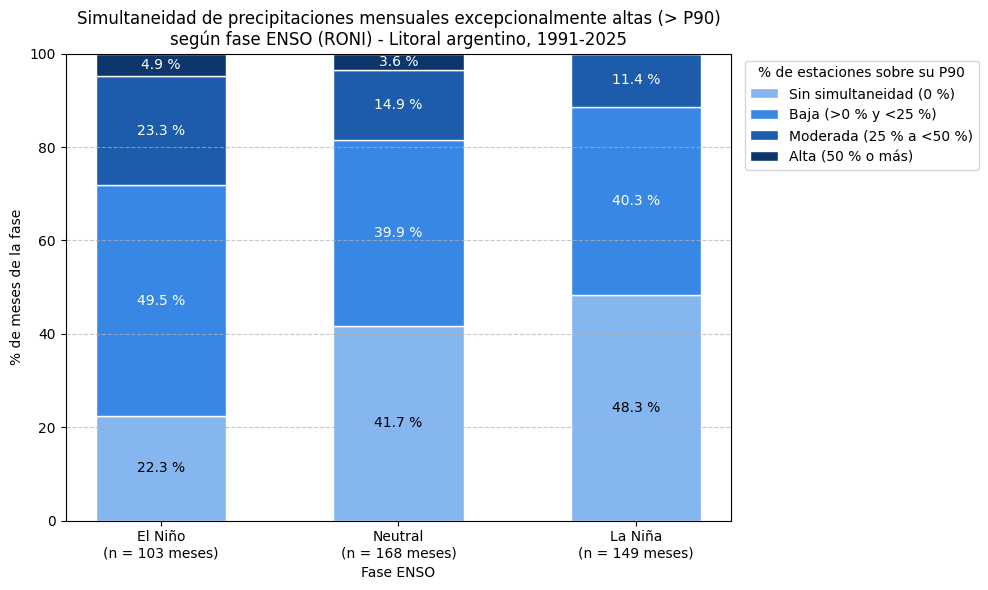

In [143]:
# GRÁFICO 1 - Simultaneidad de precipitaciones mensuales excepcionalmente altas según fase ENSO (1991-2025)

#paso 1 - partimos de nuestra base final (solo meses completos, con P90 por estación y mes calendario)
datos_g1 = smn_litoral_extremos.copy()

#paso 2 - agrupamos por año y mes para tener un registro por cada mes del período
#contamos cuántas estaciones tienen datos ese mes y cuántas superaron su P90
simultaneidad = datos_g1.groupby(["ANIO", "MES"]).agg(
    estaciones_con_datos=("EXTREMO_P90", "count"),
    estaciones_sobre_p90=("EXTREMO_P90", "sum"),
    fase_enso=("FASE_ENSO", "first")
).reset_index()

#paso 3 - creamos una nueva variable a partir de otras: el % de estaciones que superaron su P90
simultaneidad["pct_estaciones_p90"] = simultaneidad["estaciones_sobre_p90"] * 100 / simultaneidad["estaciones_con_datos"]

#paso 4 - generamos una columna que clasifique cada mes según su nivel de simultaneidad
simultaneidad.loc[simultaneidad["pct_estaciones_p90"] == 0, "nivel_simultaneidad"] = "Sin simultaneidad (0 %)"

simultaneidad.loc[(0 < simultaneidad["pct_estaciones_p90"]) & (simultaneidad["pct_estaciones_p90"] < 25), "nivel_simultaneidad"] = "Baja (>0 % y <25 %)"

simultaneidad.loc[(25 <= simultaneidad["pct_estaciones_p90"]) & (simultaneidad["pct_estaciones_p90"] < 50), "nivel_simultaneidad"] = "Moderada (25 % a <50 %)"

simultaneidad.loc[simultaneidad["pct_estaciones_p90"] >= 50, "nivel_simultaneidad"] = "Alta (50 % o más)"

#controlamos: deberían ser 420 meses (35 años x 12 meses)
print("Meses analizados:", len(simultaneidad))
print("Estaciones con datos por mes: mínimo", simultaneidad["estaciones_con_datos"].min(),
      "- máximo", simultaneidad["estaciones_con_datos"].max())

#paso 5 - contamos cuántos meses de cada fase hay en cada nivel de simultaneidad
fases = ["El Niño", "Neutral", "La Niña"]
niveles = ["Sin simultaneidad (0 %)", "Baja (>0 % y <25 %)", "Moderada (25 % a <50 %)", "Alta (50 % o más)"]

conteo = simultaneidad.groupby(["fase_enso", "nivel_simultaneidad"])["MES"].count().unstack(fill_value=0)
conteo = conteo.reindex(index=fases, columns=niveles, fill_value=0)   #ordenamos filas y columnas

#paso 6 - pasamos los conteos a porcentaje del total de meses de cada fase (cada barra suma 100 %)
meses_por_fase = conteo.sum(axis=1)
porcentajes = conteo.div(meses_por_fase, axis=0) * 100

print("\nCantidad de meses por fase:")
print(meses_por_fase)
print("\n% de meses de cada fase según nivel de simultaneidad:")
display(porcentajes.round(1))

# Gráfica de barras apiladas al 100 %

indice = np.arange(len(fases))
colores = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   #un solo color de claro (menos simultaneidad) a oscuro (más)

plt.figure(figsize=(10, 6))

#arrancamos con la base en cero y vamos apilando cada nivel encima del anterior
base = np.zeros(len(fases))

for nivel, color in zip(niveles, colores):
    valores = porcentajes[nivel].values
    plt.bar(indice, valores, bottom=base, color=color, label=nivel, width=0.55, edgecolor="white")

    #escribimos el % dentro de cada parte de la barra (si es muy chica no entra)
    for i in range(len(fases)):
        if valores[i] >= 3:
            plt.text(indice[i], base[i] + valores[i] / 2, f"{valores[i]:.1f} %",
                     ha="center", va="center", color="black" if color == colores[0] else "white")

    base = base + valores

#en el eje x ponemos cada fase con su cantidad de meses
etiquetas = [f"{fase}\n(n = {meses_por_fase[fase]} meses)" for fase in fases]
plt.xticks(indice, etiquetas)

plt.title("Simultaneidad de precipitaciones mensuales excepcionalmente altas (> P90)\nsegún fase ENSO (RONI) - Litoral argentino, 1991-2025")
plt.xlabel("Fase ENSO")
plt.ylabel("% de meses de la fase")
plt.ylim(0, 100)
plt.legend(title="% de estaciones sobre su P90", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig("grafico1_simultaneidad_enso.png", dpi=300, bbox_inches="tight")   #exportamos el gráfico como imagen para el informe
plt.show()


# Gráfico 2 - Frecuencia de precipitaciones excepcionales según fase ENSO

Este gráfico también aporta para responder la pregunta principal de nuestro trabajo: ¿Qué relación existe entre las fases del ENOS y la frecuencia y simultaneidad de precipitaciones mensuales excepcionalmente altas en el Litoral argentino durante 1991–2025?

Se trabajó con IA con contexto enriquecido para definir los pasos necesarios para el armado del gráfico y desarrollar el código correspondiente.

PROMPT: Actuá como un analista de datos senior. En el contexto se adjuntó el Colab y la propuesta de gráficos que armamos para r esponder tanto la pregunta principal como la secundaria. Vamos a trabajar con smn_litoral_extremos. Te iré haciendo propuestas de pasos a seguir para terminar de pulirlos y definirlos. Luego, te necesitaré ayuda para escribir el código para incorporarlo al Colab. Hazme las preguntas que consideres necesarias. El gráfico que hemos elegido con el grupo es uno de barras simples que nos permita comparar la frecuencia de precipitaciones excepcionales según fase ENSO. Podremos ver la frecuencia porcentual de precipitaciones mensuales excepcionalmente altas durante El Niño, Neutral y La Niña

In [145]:
 #============================================================
#FRECUENCIA DE PRECIPITACIONES EXCEPCIONALES
# SEGÚN FASE ENSO (P90)
# Litoral argentino | 1991–2025
# ============================================================

# 1. Verificar que estén disponibles las variables necesarias
columnas_necesarias = ["FASE_ENSO", "EXTREMO_P90"]

faltantes = [
    col for col in columnas_necesarias
    if col not in smn_litoral_extremos.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {faltantes}")

# 2. Verificar que la variable de extremos sea binaria
valores_validos = smn_litoral_extremos["EXTREMO_P90"].dropna().isin([0, 1]).all()

if not valores_validos:
    raise ValueError("EXTREMO_P90 contiene valores distintos de 0 y 1.")

# 3. Calcular frecuencias por fase ENSO
frecuencia_p90_enso = (
    smn_litoral_extremos
    .groupby("FASE_ENSO", dropna=False)
    .agg(
        OBSERVACIONES=("EXTREMO_P90", "count"),
        EVENTOS_P90=("EXTREMO_P90", "sum")
    )
    .reset_index()
)

# 4. Calcular la frecuencia porcentual
frecuencia_p90_enso["FRECUENCIA_P90_PCT"] = (
    frecuencia_p90_enso["EVENTOS_P90"]
    / frecuencia_p90_enso["OBSERVACIONES"]
    * 100
).round(2)

# 5. Ordenar las fases ENSO
orden_fases = ["La Niña", "Neutral", "El Niño"]

frecuencia_p90_enso["ORDEN"] = frecuencia_p90_enso["FASE_ENSO"].map(
    {fase: i for i, fase in enumerate(orden_fases)}
)

frecuencia_p90_enso = (
    frecuencia_p90_enso
    .sort_values("ORDEN", na_position="last")
    .drop(columns="ORDEN")
    .reset_index(drop=True)
)

# 6. Mostrar resultados
print("FRECUENCIA DE PRECIPITACIONES EXCEPCIONALES (P90)")
print("Litoral argentino | 1991–2025")
print("-" * 55)

display(frecuencia_p90_enso)

# 7. Comprobar los totales
print("\nCONTROL DE CONSISTENCIA")
print("Observaciones analizadas:",
      frecuencia_p90_enso["OBSERVACIONES"].sum())

print("Eventos P90 identificados:",
      frecuencia_p90_enso["EVENTOS_P90"].sum())

print("Frecuencia P90 global (%):",
      round(
          frecuencia_p90_enso["EVENTOS_P90"].sum()
          / frecuencia_p90_enso["OBSERVACIONES"].sum()
          * 100,
          2
      ))

FRECUENCIA DE PRECIPITACIONES EXCEPCIONALES (P90)
Litoral argentino | 1991–2025
-------------------------------------------------------


,FASE_ENSO,OBSERVACIONES,EVENTOS_P90,FRECUENCIA_P90_PCT
0,La Niña,2845,241,8.47
1,Neutral,3236,352,10.88
2,El Niño,1946,320,16.44



CONTROL DE CONSISTENCIA
Observaciones analizadas: 8027
Eventos P90 identificados: 913
Frecuencia P90 global (%): 11.37


¿Qué nos dice el 11,37 %? Significa que, considerando todas las estaciones y todos los meses completos del período 1991–2025, el 11,37 % de las observaciones estación-mes superó su correspondiente umbral P90.

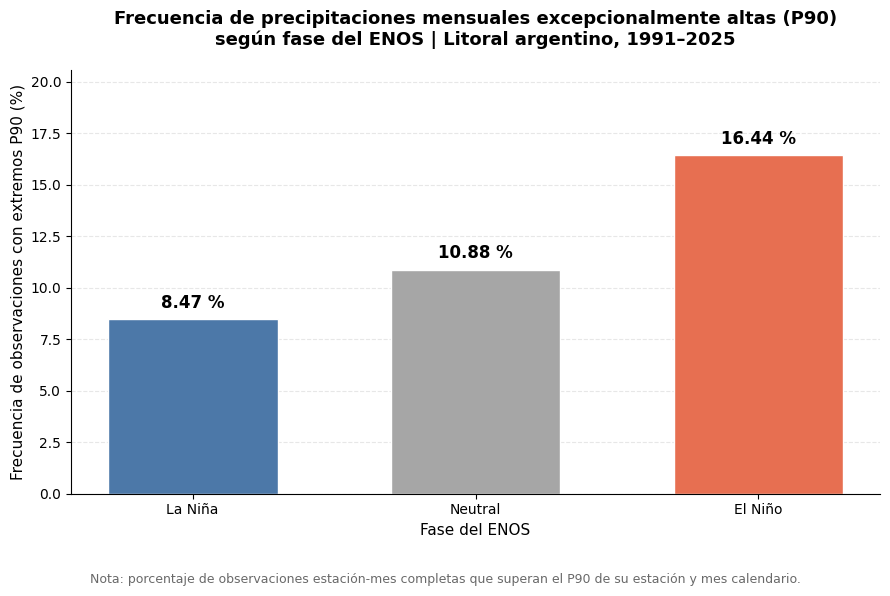

In [146]:
# GRÁFICO 2: FRECUENCIA DE PRECIPITACIONES EXCEPCIONALES (P90)
# SEGÚN FASE ENSO
# Litoral argentino | 1991–2025
# ============================================================

# 1. Preparar los datos
orden_fases = ["La Niña", "Neutral", "El Niño"]

datos_grafico = (
    frecuencia_p90_enso
    .set_index("FASE_ENSO")
    .loc[orden_fases]
    .reset_index()
)

# 2. Crear el gráfico
fig, ax = plt.subplots(figsize=(9, 6))

colores = ["#4C78A8", "#A6A6A6", "#E76F51"]

barras = ax.bar(
    datos_grafico["FASE_ENSO"],
    datos_grafico["FRECUENCIA_P90_PCT"],
    color=colores,
    width=0.6,
    edgecolor="white"
)

# 3. Incorporar los porcentajes sobre las barras
for barra, porcentaje in zip(
    barras,
    datos_grafico["FRECUENCIA_P90_PCT"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.35,
        f"{porcentaje:.2f} %",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# 4. Títulos y ejes
ax.set_title(
    "Frecuencia de precipitaciones mensuales excepcionalmente altas (P90)\n"
    "según fase del ENOS | Litoral argentino, 1991–2025",
    fontsize=13,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Fase del ENOS", fontsize=11)
ax.set_ylabel("Frecuencia de observaciones con extremos P90 (%)", fontsize=11)

# 5. Formato visual
ax.set_ylim(
    0,
    datos_grafico["FRECUENCIA_P90_PCT"].max() * 1.25
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# 6. Nota metodológica
fig.text(
    0.5, 0.02,
    "Nota: porcentaje de observaciones estación-mes completas que superan "
    "el P90 de su estación y mes calendario.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

# 7. Mostrar el gráfico
plt.show()

**Interpretación:** El análisis descriptivo muestra diferencias en la frecuencia de precipitaciones mensuales excepcionalmente altas según la fase del ENOS. Durante El Niño se registró la mayor frecuencia de observaciones que superaron el percentil 90 (16,44 %), seguida por la fase Neutral (10,88 %) y La Niña (8,47 %).

La diferencia entre El Niño y La Niña fue de 7,97 puntos porcentuales, lo que indica una mayor frecuencia relativa de precipitaciones excepcionales durante los meses clasificados como El Niño en el período estudiado.

Sin embargo, estas diferencias corresponden a las frecuencias observadas y no permiten establecer, por sí solas, si existe una asociación estadísticamente significativa. Para evaluar esta cuestión será necesario considerar la variabilidad de las precipitaciones, así como la dependencia espacial y temporal entre las observaciones.

**Vamos a evaluar estadísticamente las diferencias que acabamos de encontrar**

In [147]:
#Primero vamos a preparar los datos. Armamos una tabla en la que
#cada fila representa un mes calendario en vez de de analizar
#las 8.027 observaciones estación-mes individualmente

#nos permitirá estudiar la dispersión de las frecuencias mensuales y comparar
#sus distribuciones entre El Niño, Neutral y La Niña

# 1. Agrupar las observaciones por año, mes y fase ENSO
frecuencia_mensual_p90 = (
    smn_litoral_extremos
    .groupby(["ANIO", "MES", "FASE_ENSO"], as_index=False)
    .agg(
        ESTACIONES_DISPONIBLES=("NRO_OMM", "nunique"),
        ESTACIONES_CON_EXTREMOS=("EXTREMO_P90", "sum")
    )
)

# 2. Calcular el porcentaje mensual de estaciones con extremos
frecuencia_mensual_p90["FRECUENCIA_P90_PCT"] = (
    frecuencia_mensual_p90["ESTACIONES_CON_EXTREMOS"]
    / frecuencia_mensual_p90["ESTACIONES_DISPONIBLES"]
    * 100
)

# 3. Crear una fecha mensual para ordenar cronológicamente
frecuencia_mensual_p90["FECHA"] = pd.to_datetime(
    dict(
        year=frecuencia_mensual_p90["ANIO"],
        month=frecuencia_mensual_p90["MES"],
        day=1
    )
)

frecuencia_mensual_p90 = (
    frecuencia_mensual_p90
    .sort_values("FECHA")
    .reset_index(drop=True)
)

# 4. Controles de consistencia
assert not frecuencia_mensual_p90["FECHA"].duplicated().any(), \
    "Se encontraron meses duplicados."

assert (
    frecuencia_mensual_p90["ESTACIONES_CON_EXTREMOS"].sum()
    == smn_litoral_extremos["EXTREMO_P90"].sum()
), "No coincide el total de eventos P90."

assert (
    frecuencia_mensual_p90["ESTACIONES_DISPONIBLES"].sum()
    == len(smn_litoral_extremos)
), "No coincide el total de observaciones estación-mes."

# 5. Mostrar resultados
print("CONTROL DE CONSISTENCIA")
print("Meses analizados:", len(frecuencia_mensual_p90))
print(
    "Observaciones estación-mes:",
    frecuencia_mensual_p90["ESTACIONES_DISPONIBLES"].sum()
)
print(
    "Eventos P90:",
    frecuencia_mensual_p90["ESTACIONES_CON_EXTREMOS"].sum()
)

print("\nESTACIONES DISPONIBLES POR MES")
display(
    frecuencia_mensual_p90["ESTACIONES_DISPONIBLES"].describe()
)

print("\nPRIMEROS 10 MESES")
display(frecuencia_mensual_p90.head(10))

CONTROL DE CONSISTENCIA
Meses analizados: 420
Observaciones estación-mes: 8027
Eventos P90: 913

ESTACIONES DISPONIBLES POR MES


,ESTACIONES_DISPONIBLES
count,420.000000
mean,19.111905
std,0.924011
min,16.000000
25%,18.000000
50%,19.000000
75%,20.000000
max,20.000000



PRIMEROS 10 MESES


,ANIO,MES,FASE_ENSO,ESTACIONES_DISPONIBLES,ESTACIONES_CON_EXTREMOS,FRECUENCIA_P90_PCT,FECHA
0,1991,1,Neutral,19,1,5.263158,1991-01-01
1,1991,2,Neutral,19,0,0.000000,1991-02-01
2,1991,3,Neutral,19,2,10.526316,1991-03-01
3,1991,4,Neutral,19,4,21.052632,1991-04-01
4,1991,5,El Niño,19,5,26.315789,1991-05-01
5,1991,6,El Niño,18,10,55.555556,1991-06-01
6,1991,7,El Niño,18,2,11.111111,1991-07-01
7,1991,8,El Niño,18,0,0.000000,1991-08-01
8,1991,9,El Niño,19,2,10.526316,1991-09-01
9,1991,10,El Niño,17,0,0.000000,1991-10-01


Este paso, si bien es necesario para preparar los datos, también nos permite corroborar la sospecha que teníamos al analizar el gráfico anterior de barras.

Vemos, por ejemplo, que durante junio de 1991, clasificado como El Niño, 10 de las 18 estaciones disponibles superaron P90.

Esto representa el 55,56 % de las estaciones.

Sin embargo, durante agosto del mismo año, también clasificado como El Niño, ninguna estación superó P90.

Esta diferencia ratifica nuestras sospechas: dentro de una misma fase ENSO puede existir una variabilidad mensual considerable.

In [148]:
#Vamos a estudiar la Distribución de las frecuencias mensuales P90 según fase ENSO


# 1. Definir el orden de las fases
orden_fases = ["La Niña", "Neutral", "El Niño"]

# 2. Calcular estadísticas descriptivas por fase
dispersion_p90_enso = (
    frecuencia_mensual_p90
    .groupby("FASE_ENSO")["FRECUENCIA_P90_PCT"]
    .agg(
        MESES="count",
        MEDIA="mean",
        MEDIANA="median",
        DESVIO_ESTANDAR="std",
        MINIMO="min",
        MAXIMO="max"
    )
    .reindex(orden_fases)
    .round(2)
)

# 3. Calcular cuartiles
cuartiles = (
    frecuencia_mensual_p90
    .groupby("FASE_ENSO")["FRECUENCIA_P90_PCT"]
    .quantile([0.25, 0.75])
    .unstack()
    .reindex(orden_fases)
)

cuartiles.columns = ["Q1", "Q3"]

dispersion_p90_enso = (
    dispersion_p90_enso
    .join(cuartiles)
    .round(2)
)

# 4. Mostrar tabla
print("DISTRIBUCIÓN DE FRECUENCIAS MENSUALES P90 SEGÚN FASE ENSO")
display(dispersion_p90_enso)

DISTRIBUCIÓN DE FRECUENCIAS MENSUALES P90 SEGÚN FASE ENSO


,MESES,MEDIA,MEDIANA,DESVIO_ESTANDAR,MINIMO,MAXIMO,Q1,Q3
FASE_ENSO,,,,,,,,
La Niña,149,8.48,5.00,11.60,0.0,45.00,0.0,15.00
Neutral,168,10.88,5.00,14.06,0.0,60.00,0.0,20.00
El Niño,103,16.31,11.11,16.53,0.0,66.67,5.0,25.66


**Intepretación:** La tabla presenta las estadísticas descriptivas de la proporción mensual de estaciones meteorológicas con precipitaciones superiores al percentil 90 (P90), diferenciadas según la fase del ENOS, para el período 1991–2025.

Se observa que El Niño presenta la mayor frecuencia media mensual de precipitaciones excepcionales (16,31 %), seguido por la fase Neutral (10,88 %) y La Niña (8,48 %). Las medianas muestran una tendencia similar: durante El Niño alcanzan el 11,11 %, mientras que en Neutral y La Niña se ubican en el 5 %.

Sin embargo, los desvíos estándar son elevados en relación con las medias: 16,53 puntos porcentuales durante El Niño, 14,06 en Neutral y 11,60 en La Niña. Esto indica una considerable variabilidad mensual dentro de cada fase.

Los cuartiles también muestran diferencias. Durante El Niño, el 50 % central de las observaciones se concentra entre el 5 % y el 25,66 % de estaciones con precipitaciones excepcionales. En Neutral, este intervalo se extiende entre el 0 % y el 20 %, mientras que en La Niña se encuentra entre el 0 % y el 15 %.

**En síntesis,** los resultados descriptivos indican que los meses clasificados como El Niño presentan, en promedio, una mayor proporción de estaciones con precipitaciones excepcionalmente altas. No obstante, la variabilidad observada dentro de cada fase hace necesario complementar este análisis con pruebas estadísticas que permitan evaluar si las diferencias encontradas cuentan con respaldo estadístico.

In [149]:
#Análisis estadísitico - modelo de regresión con errores estándar robustos a la
#autocorrelación temporal mediante Newey-West (HAC)

# ============================================================
#ASOCIACIÓN ENTRE FASE ENSO Y FRECUENCIA MENSUAL P90
# Regresión lineal con errores estándar HAC (Newey-West)
# Litoral argentino | 1991–2025
# ============================================================

import statsmodels.formula.api as smf

# 1. Preparar los datos sin modificar el DataFrame original
datos_regresion = (
    frecuencia_mensual_p90
    .sort_values("FECHA")
    .copy()
)

# 2. Verificar que no existan valores faltantes
columnas_modelo = ["FRECUENCIA_P90_PCT", "FASE_ENSO"]

if datos_regresion[columnas_modelo].isna().any().any():
    raise ValueError("Existen valores faltantes en las variables del modelo.")

# 3. Ajustar el modelo con fase Neutral como referencia
modelo_hac = smf.ols(
    formula=(
        "FRECUENCIA_P90_PCT ~ "
        "C(FASE_ENSO, Treatment(reference='Neutral'))"
    ),
    data=datos_regresion
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

# 4. Mostrar resultados completos
print("REGRESIÓN: FRECUENCIA MENSUAL P90 SEGÚN FASE ENSO")
print("Referencia: fase Neutral")
print("Errores estándar HAC (Newey-West), 12 rezagos")
print("-" * 65)

print(modelo_hac.summary())

# 5. Mostrar tabla resumida
intervalos = modelo_hac.conf_int()

resultados_hac = pd.DataFrame({
    "COEFICIENTE": modelo_hac.params,
    "ERROR_ESTANDAR_HAC": modelo_hac.bse,
    "P_VALOR": modelo_hac.pvalues,
    "IC95_INF": intervalos[0],
    "IC95_SUP": intervalos[1]
}).round(4)

print("\nTABLA RESUMEN DE RESULTADOS")
display(resultados_hac)

REGRESIÓN: FRECUENCIA MENSUAL P90 SEGÚN FASE ENSO
Referencia: fase Neutral
Errores estándar HAC (Newey-West), 12 rezagos
-----------------------------------------------------------------
                            OLS Regression Results                            
Dep. Variable:     FRECUENCIA_P90_PCT   R-squared:                       0.045
Model:                            OLS   Adj. R-squared:                  0.040
Method:                 Least Squares   F-statistic:                     5.353
Date:                Fri, 30 Oct 2026   Prob (F-statistic):            0.00506
Time:                        00:29:51   Log-Likelihood:                -1700.4
No. Observations:                 420   AIC:                             3407.
Df Residuals:                     417   BIC:                             3419.
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                       

,COEFICIENTE,ERROR_ESTANDAR_HAC,P_VALOR,IC95_INF,IC95_SUP
Intercept,10.8773,0.9870,0.0000,8.9427,12.8118
"C(FASE_ENSO, Treatment(reference='Neutral'))[T.El Niño]",5.4330,2.2529,0.0159,1.0173,9.8487
"C(FASE_ENSO, Treatment(reference='Neutral'))[T.La Niña]",-2.3923,1.4881,0.1079,-5.3089,0.5242


**Interpretación:** Los resultados muestran que, durante El Niño, la proporción mensual de estaciones con precipitaciones superiores a P90 fue, en promedio, 5,43 puntos porcentuales mayor que durante Neutral. Esta diferencia resultó estadísticamente significativa (p = 0,0159). En cambio, durante La Niña, la frecuencia fue 2,39 puntos porcentuales menor que en Neutral, aunque esta diferencia no alcanzó significación estadística (p = 0,1079).

El modelo resultó significativo en términos globales (p = 0,0051), pero presentó un R² de 0,045, lo que indica que la fase del ENOS explica aproximadamente el 4,5 % de la variabilidad mensual observada.

En síntesis, se encontró evidencia estadística de una mayor frecuencia de precipitaciones excepcionales durante El Niño respecto de Neutral, aunque la capacidad explicativa del modelo es limitada.

**El siguiente paso es la comparación directa entre El Niño y La Niña.**

In [150]:
#COMPARACIÓN DIRECTA EL NIÑO VS. LA NIÑA

# 1. Identificar los coeficientes del modelo
nombres_coeficientes = list(modelo_hac.params.index)

coef_nino = next(
    nombre for nombre in nombres_coeficientes
    if "[T.El Niño]" in nombre
)

coef_nina = next(
    nombre for nombre in nombres_coeficientes
    if "[T.La Niña]" in nombre
)

# 2. Construir el contraste lineal:
# H0: coeficiente El Niño - coeficiente La Niña = 0

R = np.zeros(len(nombres_coeficientes))

R[nombres_coeficientes.index(coef_nino)] = 1
R[nombres_coeficientes.index(coef_nina)] = -1

# 3. Ejecutar el contraste con la covarianza HAC
contraste_nino_nina = modelo_hac.t_test(R)

# 4. Mostrar resultado completo
print("CONTRASTE ESTADÍSTICO: EL NIÑO VS. LA NIÑA")
print("H0: ambas fases presentan la misma frecuencia media mensual")
print("Errores estándar HAC (Newey-West), 12 rezagos")
print("-" * 65)

print(contraste_nino_nina)

# 5. Construir tabla resumida
intervalo = contraste_nino_nina.conf_int()[0]

resultado_contraste = pd.DataFrame({
    "COMPARACION": ["El Niño - La Niña"],
    "DIFERENCIA_PP": [float(np.asarray(contraste_nino_nina.effect).item())],
    "ERROR_ESTANDAR_HAC": [float(np.asarray(contraste_nino_nina.sd).item())],
    "P_VALOR": [float(np.asarray(contraste_nino_nina.pvalue).item())],
    "IC95_INF": [float(intervalo[0])],
    "IC95_SUP": [float(intervalo[1])]
}).round(4)

print("\nTABLA RESUMEN")
display(resultado_contraste)

CONTRASTE ESTADÍSTICO: EL NIÑO VS. LA NIÑA
H0: ambas fases presentan la misma frecuencia media mensual
Errores estándar HAC (Newey-West), 12 rezagos
-----------------------------------------------------------------
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             7.8253      2.402      3.257      0.001       3.117      12.534

TABLA RESUMEN


,COMPARACION,DIFERENCIA_PP,ERROR_ESTANDAR_HAC,P_VALOR,IC95_INF,IC95_SUP
0,El Niño - La Niña,7.8253,2.4023,0.0011,3.117,12.5337


**Interpretación:** El contraste estadístico entre las fases El Niño y La Niña mostró una diferencia de 7,83 puntos porcentuales en la proporción mensual de estaciones con precipitaciones superiores a P90, favorable a El Niño. Esta diferencia resultó estadísticamente significativa (p = 0,0011), con un intervalo de confianza del 95 % comprendido entre 3,12 y 12,53 puntos porcentuales.

Este resultado indica que, durante el período 1991–2025, los meses clasificados como El Niño presentaron, en promedio, una mayor proporción de estaciones con precipitaciones excepcionalmente altas que los meses clasificados como La Niña.

Considerando las comparaciones realizadas, se encontró evidencia estadística de diferencias entre El Niño y las fases Neutral y La Niña. En cambio, la diferencia entre La Niña y Neutral no resultó significativa al nivel del 5 %.

**En conjunto,** los resultados respaldan la existencia de una asociación entre las fases del ENOS y la frecuencia mensual de precipitaciones excepcionales en el Litoral argentino, aunque no permiten establecer una relación causal.